# Bài 3: Naive Bayes
**Học máy ứng dụng — Trường Đại học Văn Lang, Khoa Công nghệ Thông tin**

Notebook này làm lại toàn bộ bài thực hành `Lab03_Naive_Bayes.pdf` trên hai bộ dữ liệu:

- `tin_nhan.csv` — 300 tin nhắn, 2 cột (`noi_dung`, `la_rac`), dùng cho bộ lọc tin rác.
- `sinh_vien.csv` — 120 sinh viên của bài 2, dùng lại để so Naive Bayes với hồi quy logistic
  trên **cùng một đề bài**.

| Phần | Nội dung | Tương ứng trong tài liệu |
|---|---|---|
| A | 5 bước của bài thực hành | Mục 2 → Mục 6 (`d1` … `d5`) |
| B | 6 bài tập nộp | Mục 7 |

Hai buổi trước, máy học bằng cách vẽ một **ranh giới** rồi dò cho ranh giới đó ngày càng khớp.
Buổi này máy làm việc khác hẳn: nó **mô tả mỗi lớp trông như thế nào**, rồi hỏi lớp nào dễ sinh
ra mẫu đang xét hơn.

**Cách dùng:** chạy lần lượt từ trên xuống (`Shift + Enter`). Mỗi bước đều in ra con số để
đối chiếu với tài liệu. Mọi hình vẽ đều được lưu thêm một bản vào thư mục `images/` cạnh notebook.

**Thư viện cần có:** `numpy`, `pandas`, `matplotlib`, `scikit-learn`.

```
pip install numpy pandas matplotlib scikit-learn
```

## 0. Chuẩn bị môi trường

Tài liệu quy ước dữ liệu nằm ở `data/tin_nhan.csv` và `data/sinh_vien.csv`; nếu notebook đặt
cạnh hai tệp CSV thì đường dẫn chỉ là tên tệp. Hàm `tim_tep` tự dò cả hai chỗ.

Hàm `luu_hinh` gọi `plt.savefig` **trước** `plt.show()`, vì `show` đóng hình lại và lưu sau đó
sẽ được một tệp trắng.

In [1]:
# -*- coding: utf-8 -*-
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def tim_tep(ten_tep):
    """Ưu tiên bố cục data/ của tài liệu, nếu không có thì lấy tệp cùng thư mục."""
    for duong_dan in (Path("data") / ten_tep, Path(ten_tep)):
        if duong_dan.exists():
            return duong_dan
    raise FileNotFoundError(
        f"Khong tim thay {ten_tep}. Hay dat notebook canh tep CSV, "
        "hoac tao thu muc data/ va bo tep vao do."
    )


DUONG_DAN_TIN = tim_tep("tin_nhan.csv")
DUONG_DAN_SV = tim_tep("sinh_vien.csv")
print("Doc tin nhan tu :", DUONG_DAN_TIN.resolve())
print("Doc sinh vien tu:", DUONG_DAN_SV.resolve())

# Mọi hình vẽ được lưu thêm một bản vào images/ cạnh notebook.
THU_MUC_ANH = Path("images")
THU_MUC_ANH.mkdir(exist_ok=True)


def luu_hinh(ten_tep):
    """Lưu hình đang vẽ vào images/ rồi mới hiện ra màn hình."""
    plt.savefig(THU_MUC_ANH / ten_tep, dpi=150, bbox_inches="tight")
    plt.show()


# DejaVu Sans (phông mặc định của matplotlib) có đủ dấu tiếng Việt nên hình vẽ hiện đúng chữ.
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Màu dùng xuyên suốt bài: đỏ cho tin rác / rớt môn, xanh đậm cho tin thường / qua môn.
MAU_RAC = "#c53030"
MAU_THUONG = "#1a365d"

Doc tin nhan tu : D:\HOC\HMUD\TH\03. Naive Bayes\tin_nhan.csv
Doc sinh vien tu: D:\HOC\HMUD\TH\03. Naive Bayes\sinh_vien.csv


---
# Phần A — Bài thực hành

## Bước 1 — Định lý Bayes *(Mục 2, `d1_bayes_tay.py`)*

### Một câu hỏi nên tự trả lời trước

Một căn bệnh có ở **1 phần trăm** dân số. Xét nghiệm rất tốt: người có bệnh thì 99 phần trăm cho
kết quả dương tính, người không bệnh thì 99 phần trăm cho kết quả âm tính. Sinh viên nhận kết quả
**dương tính**. Khả năng có bệnh thật là bao nhiêu?

Hầu hết mọi người trả lời khoảng 99 phần trăm. Đáp án đúng là **0.5** — chỉ năm mươi năm mươi.

### Giải bằng cách đếm người *(Bảng 2)*

Bỏ hẳn công thức đi và đếm trên một nhóm 10000 người:

| | Dương tính | Âm tính | Tổng |
|---|---:|---:|---:|
| Có bệnh | 99 | 1 | 100 |
| Không bệnh | 99 | 9801 | 9900 |
| **Tổng** | **198** | 9802 | 10000 |

Nhìn cột dương tính: có 198 người, trong đó chỉ 99 người bệnh thật. Vậy tỷ lệ là $99/198 = 0.5$.

> **Vì sao trực giác sai:** vì bệnh quá hiếm. Nhóm không bệnh đông gấp 99 lần nhóm có bệnh, nên dù
> chỉ sai 1 phần trăm, nhóm đó vẫn tạo ra đúng 99 ca dương tính giả — bằng chằn chặn số ca dương
> tính thật, nên hai nhóm hoà nhau.

### Công thức

$$\mathbb{P}(A \mid B) = \frac{\mathbb{P}(B \mid A)\,\mathbb{P}(A)}{\mathbb{P}(B)}$$

| Thành phần | Tên gọi | Trong ví dụ xét nghiệm |
|---|---|---|
| $\mathbb{P}(A)$ | Tiên nghiệm (*prior*) | Tỷ lệ mắc bệnh, bằng 0.01 |
| $\mathbb{P}(B \mid A)$ | Khả năng (*likelihood*) | Độ nhạy của xét nghiệm, bằng 0.99 |
| $\mathbb{P}(B)$ | Bằng chứng (*evidence*) | Tỷ lệ dương tính chung, bằng 0.0198 |
| $\mathbb{P}(A \mid B)$ | Hậu nghiệm (*posterior*) | Điều ta muốn biết, bằng 0.5 |

> ⚠️ **Lỗi tư duy phổ biến nhất:** đảo hai vế của gạch đứng rồi tưởng giá trị không đổi.
> $\mathbb{P}(\text{dương} \mid \text{bệnh}) = 0.99$ nhưng $\mathbb{P}(\text{bệnh} \mid \text{dương}) = 0.5$.
> Hai con số cách nhau rất xa, và định lý Bayes chính là công cụ đổi chiều cho đúng.

Hàm `bayes` dưới đây nhận ba con số và trả về hậu nghiệm. Mẫu số không phải nhập vào mà được dựng
từ hai nhánh — nhánh $A$ đúng và nhánh $A$ sai. Cách viết này gọi là **công thức xác suất toàn
phần**, nhờ nó ta không phải tự tính $\mathbb{P}(B)$.

In [2]:
"""Bước 1: tính định lý Bayes bằng tay, không cần thư viện học máy."""


def bayes(tien_nghiem, kha_nang, kha_nang_nguoc):
    """Tra ve xac suat hau nghiem.

    tien_nghiem      : P(A), niem tin truoc khi co bang chung
    kha_nang         : P(B | A), bang chung xuat hien khi A dung
    kha_nang_nguoc   : P(B | khong A), bang chung xuat hien khi A sai
    """
    tu_so = kha_nang * tien_nghiem
    mau_so = tu_so + kha_nang_nguoc * (1 - tien_nghiem)
    return tu_so / mau_so


print("Vi du 1: xet nghiem benh")
print("  Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.")
p = bayes(tien_nghiem=0.01, kha_nang=0.99, kha_nang_nguoc=0.01)
print(f"  Duong tinh thi kha nang co benh that = {p:.4f}")
print()

# Giữ nguyên chất lượng xét nghiệm, chỉ đổi tỷ lệ mắc bệnh
print("Cung xet nghiem do, doi ty le mac benh:")
print("  Ty le mac benh    Hau nghiem khi duong tinh")
for ty_le in [0.001, 0.01, 0.05, 0.10, 0.50]:
    print(f"    {ty_le:6.3f}              {bayes(ty_le, 0.99, 0.01):.4f}")
print()

print("Vi du 2: hai day chuyen san xuat")
print("  Day A lam 80 phan tram san pham, ty le loi 1 phan tram.")
print("  Day B lam 20 phan tram san pham, ty le loi 5 phan tram.")
# Ở đây "A đúng" nghĩa là sản phẩm đến từ dây B
p_b = bayes(tien_nghiem=0.20, kha_nang=0.05, kha_nang_nguoc=0.01)
print(f"  Nhat duoc san pham loi, kha nang no tu day B = {p_b:.4f}")
print()

print("Kiem lai bang cach dem tren 1000 san pham:")
loi_a = 800 * 0.01
loi_b = 200 * 0.05
print(f"  Day A: 800 san pham, {loi_a:.0f} cai loi")
print(f"  Day B: 200 san pham, {loi_b:.0f} cai loi")
tong_loi = loi_a + loi_b
print(f"  Ty le tu day B = {loi_b} / {tong_loi} = {loi_b / tong_loi:.4f}")

Vi du 1: xet nghiem benh
  Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.
  Duong tinh thi kha nang co benh that = 0.5000

Cung xet nghiem do, doi ty le mac benh:
  Ty le mac benh    Hau nghiem khi duong tinh
     0.001              0.0902
     0.010              0.5000
     0.050              0.8390
     0.100              0.9167
     0.500              0.9900

Vi du 2: hai day chuyen san xuat
  Day A lam 80 phan tram san pham, ty le loi 1 phan tram.
  Day B lam 20 phan tram san pham, ty le loi 5 phan tram.
  Nhat duoc san pham loi, kha nang no tu day B = 0.5556

Kiem lai bang cach dem tren 1000 san pham:
  Day A: 800 san pham, 8 cai loi
  Day B: 200 san pham, 10 cai loi
  Ty le tu day B = 10.0 / 18.0 = 0.5556


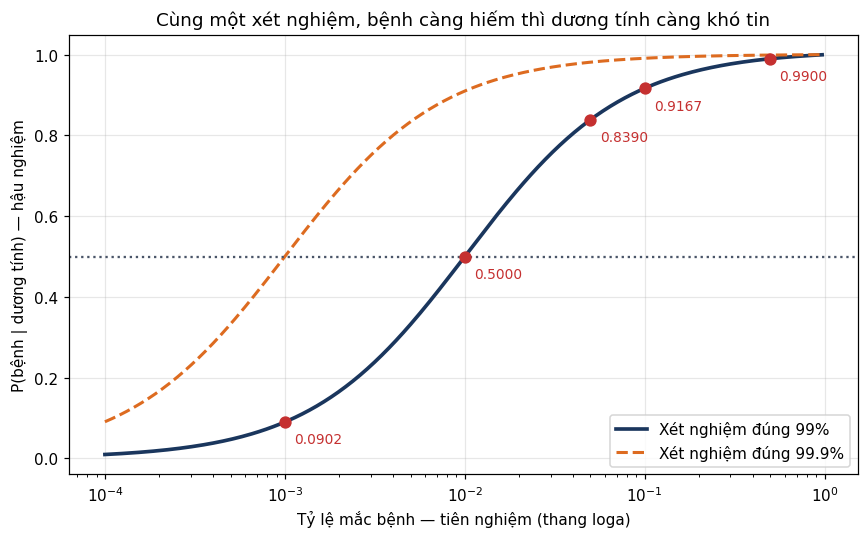

In [3]:
# Vẽ thêm: hậu nghiệm thay đổi thế nào khi chỉ đổi tỷ lệ mắc bệnh
luoi_ty_le = np.logspace(-4, 0, 300)[:-1]
plt.figure()
plt.plot(luoi_ty_le, bayes(luoi_ty_le, 0.99, 0.01), color=MAU_THUONG, linewidth=2.4,
         label="Xét nghiệm đúng 99%")
plt.plot(luoi_ty_le, bayes(luoi_ty_le, 0.999, 0.001), "--", color="#dd6b20", linewidth=2,
         label="Xét nghiệm đúng 99.9%")
for ty_le in [0.001, 0.01, 0.05, 0.10, 0.50]:
    plt.scatter([ty_le], [bayes(ty_le, 0.99, 0.01)], s=50, color=MAU_RAC, zorder=5)
    plt.annotate(f"{bayes(ty_le, 0.99, 0.01):.4f}", (ty_le, bayes(ty_le, 0.99, 0.01)),
                 textcoords="offset points", xytext=(6, -14), fontsize=9, color=MAU_RAC)
plt.axhline(0.5, linestyle=":", color="#4a5568")
plt.xscale("log")
plt.xlabel("Tỷ lệ mắc bệnh — tiên nghiệm (thang loga)")
plt.ylabel("P(bệnh | dương tính) — hậu nghiệm")
plt.title("Cùng một xét nghiệm, bệnh càng hiếm thì dương tính càng khó tin")
plt.legend(loc="lower right")
plt.tight_layout()
luu_hinh("buoc1_hau_nghiem_theo_tien_nghiem.png")

**Đọc kết quả:**

- Ví dụ 1 ra đúng **0.5000**, khớp với cách đếm 99/198.
- Bảng giữa là phần đáng suy nghĩ nhất. **Chất lượng xét nghiệm không đổi chút nào**, chỉ có tỷ lệ
  mắc bệnh đổi, mà hậu nghiệm chạy từ **0.0902** lên **0.9900**. Hình trên cho thấy cả đường cong: với
  bệnh hiếm cỡ 1 phần nghìn, một kết quả dương tính chỉ đáng tin chưa tới 10 phần trăm. Muốn kéo
  điểm 0.001 lên được 0.5 thì phải có xét nghiệm đúng tới 99.9 phần trăm (đường nét đứt).
- Ví dụ 2: dây B chỉ làm 20% sản phẩm nhưng gây ra **10 trong 18** cái lỗi, nên nhặt được một sản
  phẩm lỗi thì khả năng nó từ dây B là **0.5556**. Đếm trên 1000 sản phẩm cho đúng con số đó.

> **Bài học mang sang phần sau:** xác suất tiên nghiệm quan trọng ngang với bằng chứng. Trong phân
> loại, tiên nghiệm chính là **tỷ lệ của từng lớp trong dữ liệu huấn luyện**, và Naive Bayes luôn
> nhân nó vào. Đó là lý do một lớp hiếm rất khó được mô hình chọn (Bài tập 6 sẽ kiểm chứng).

---
## Bước 2 — Biến văn bản thành số *(Mục 3, `d2_tui_tu.py`)*

Tệp `tin_nhan.csv` có 300 dòng và 2 cột. Cột `noi_dung` là chữ, cột `la_rac` là nhãn với **1 nghĩa
là tin rác** và **0 nghĩa là tin thường**.

> **Về bộ số liệu:** đây là số liệu mô phỏng cho mục đích giảng dạy. Tin nhắn được ghép từ các nhóm
> từ đặt sẵn, và có khoảng một phần năm tin rác cố tình viết như tin thường — nếu hai lớp tách bạch
> hoàn toàn thì mô hình nào cũng đạt 100 phần trăm và buổi học không còn gì để bàn.

### Túi từ *(Bảng 4)*

Máy không đọc được chữ, nên việc đầu tiên là đổi mỗi tin nhắn thành một dãy số. Cách đơn giản nhất
là **túi từ** (*bag of words*): lập một từ điển gồm mọi từ xuất hiện trong kho, rồi mỗi tin nhắn thành
một dòng đếm số lần từng từ xuất hiện.

| Tin nhắn | trúng | thưởng | họp | nhóm | Nhãn |
|---|---:|---:|---:|---:|---|
| trúng thưởng trúng ngay | 2 | 1 | 0 | 0 | rác |
| họp nhóm chiều mai | 0 | 0 | 1 | 1 | thường |
| nhóm mình trúng thưởng | 1 | 1 | 0 | 1 | rác |

> ⚠️ **Túi từ bỏ mất thứ tự từ.** Câu *chó cắn người* và câu *người cắn chó* cho ra đúng một túi từ
> giống nhau. Với bài lọc tin rác thì mất mát này chấp nhận được, vì bản thân từ ngữ đã đủ tố cáo.
> Với bài phân tích cảm xúc hay dịch máy thì thứ tự quan trọng hơn nhiều, và túi từ không còn đủ.

**Một tham số cần chú ý:** mặc định `CountVectorizer` bỏ qua mọi từ chỉ có một ký tự (như chữ `ạ`)
và cắt chữ theo quy tắc riêng. Với tiếng Việt, ta chỉ định `token_pattern=r"(?u)\S+"` để tách từ
đơn giản bằng khoảng trắng.

In [4]:
"""Bước 2: đọc kho tin nhắn và biến văn bản thành bảng số."""

from sklearn.feature_extraction.text import CountVectorizer

df = pd.read_csv(DUONG_DAN_TIN)

print("Kich thuoc bang:", df.shape)
print()
print("So tin theo nhan (1 la rac, 0 la thuong):")
print(df["la_rac"].value_counts())
print()
print("Ty le tin rac:", round(df["la_rac"].mean(), 4))
print()

print("Ba tin nhan dau tien:")
for i in range(3):
    print(f"  [{df.la_rac[i]}] {df.noi_dung[i]}")
print()

# token_pattern mặc định của scikit-learn bỏ mất từ một ký tự,
# nên ta chỉ định tách từ bằng khoảng trắng cho đơn giản.
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])

print("Kich thuoc bang dem tu:", X.shape)
print("So tu trong tu dien:", len(vec.vocabulary_))
print()

# Đếm tổng số lần xuất hiện của từng từ, tách theo hai lớp
dem = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())
dem["la_rac"] = df["la_rac"]
tong = dem.groupby("la_rac").sum().T
tong.columns = ["thuong", "rac"]

print("Muoi tu xuat hien nhieu nhat trong tin rac:")
print(tong.sort_values("rac", ascending=False).head(10))
print()
print("Muoi tu xuat hien nhieu nhat trong tin thuong:")
print(tong.sort_values("thuong", ascending=False).head(10))

Kich thuoc bang: (300, 2)

So tin theo nhan (1 la rac, 0 la thuong):
la_rac
0    180
1    120
Name: count, dtype: int64

Ty le tin rac: 0.4

Ba tin nhan dau tien:
  [0] cáo gửi cáo thầy nhóm cáo gửi có cho
  [1] miễn giảm ngay hạn miễn tay nhé thưởng cho nhanh
  [0] cho bạn mai gửi nhóm bài chiều

Kich thuoc bang dem tu: (300, 40)
So tu trong tu dien: 40

Muoi tu xuat hien nhieu nhat trong tin rac:
       thuong  rac
tay         3   48
ngay        4   47
nhanh       9   44
chót        6   43
giảm        6   42
lúc        39   42
quà         8   41
phí         6   40
click       5   40
tặng        7   39

Muoi tu xuat hien nhieu nhat trong tin thuong:
       thuong  rac
thầy       74    7
bài        73    4
cáo        72    8
chiều      68    8
ạ          65    7
tài        64   11
tập        63    6
gửi        61   10
lớp        60    2
nhóm       58    7


**Đọc kết quả:** bảng đếm có kích thước **300 × 40**, nghĩa là 300 tin nhắn và một từ điển 40 từ.
Mỗi tin nhắn giờ là một dãy 40 con số, và máy làm việc được với nó.

Hai bảng cuối cho thấy điều quan trọng nhất. Các từ như `tay`, `ngay`, `nhanh`, `click` xuất hiện rất
nhiều trong tin rác nhưng gần như vắng bóng ở tin thường. Ngược lại các từ như `báo`, `cáo`, `thầy`
chỉ thấy ở tin thường.

> 💡 **Một chi tiết đáng để ý:** từ `lúc` xuất hiện 39 lần ở tin thường và 42 lần ở tin rác, gần như
> bằng nhau. Từ như vậy **không mang thông tin phân loại**, nó chỉ làm nền. Naive Bayes tự xử lý được
> chuyện này, vì xác suất của nó gần bằng nhau ở hai lớp nên nhân vào không làm lệch bên nào.

### Từ nào tố cáo tin rác mạnh nhất *(Hình 1)*

Hình dưới dùng trước mô hình ở Bước 3 (học trên 225 tin của tập học). Với mỗi từ, lấy
$\log \mathbb{P}(\text{từ} \mid \text{rác}) - \log \mathbb{P}(\text{từ} \mid \text{thường})$: số dương nghĩa
là từ đó hay gặp ở tin rác hơn, số âm nghĩa là hay gặp ở tin thường hơn.

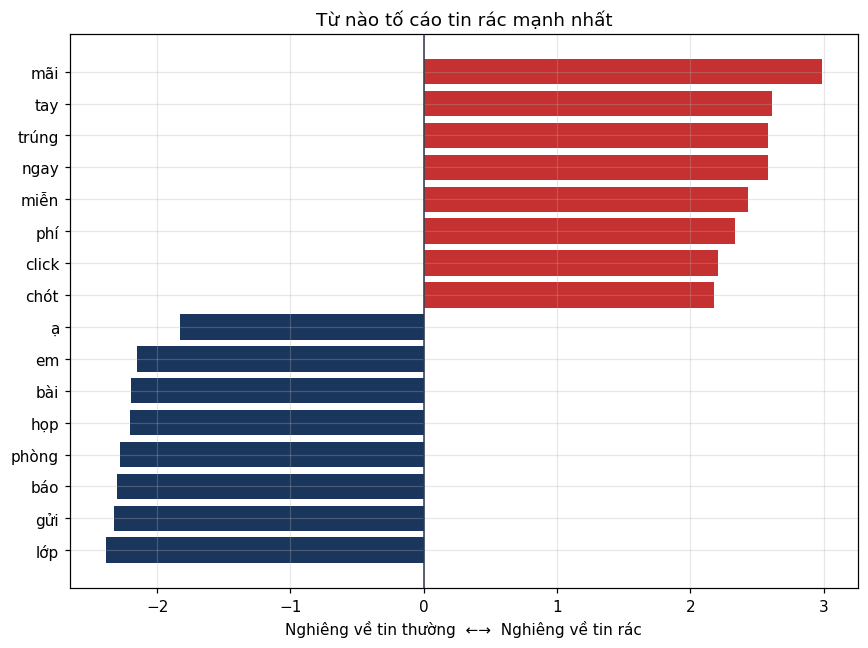

Lech manh nhat ve rac   : mãi (+2.99), tay (+2.61), trúng (+2.58)
Lech manh nhat ve thuong: lớp (-2.39), gửi (-2.32), báo (-2.30)
Tu 'luc' chi lech        : +0.35


In [5]:
# Hình 1: mức chênh lệch giữa hai lớp của từng từ (mô hình học trên tập học của Bước 3)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

X_hoc_h1, _, y_hoc_h1, _ = train_test_split(
    X, df["la_rac"], test_size=0.25, random_state=17, stratify=df["la_rac"]
)
mo_hinh_h1 = MultinomialNB().fit(X_hoc_h1, y_hoc_h1)
chenh_lech = mo_hinh_h1.feature_log_prob_[1] - mo_hinh_h1.feature_log_prob_[0]
ten_tu = vec.get_feature_names_out()

thu_tu = np.argsort(chenh_lech)
chon = np.concatenate([thu_tu[:8], thu_tu[-8:]])      # 8 từ nghiêng về thường + 8 từ nghiêng về rác

plt.figure(figsize=(8, 6))
plt.barh(range(len(chon)), chenh_lech[chon],
         color=np.where(chenh_lech[chon] > 0, MAU_RAC, MAU_THUONG))
plt.yticks(range(len(chon)), ten_tu[chon])
plt.axvline(0, color="#2d3748", linewidth=1)
plt.xlabel("Nghiêng về tin thường  ←→  Nghiêng về tin rác")
plt.title("Từ nào tố cáo tin rác mạnh nhất")
plt.tight_layout()
luu_hinh("hinh1_tu_to_cao_tin_rac.png")

print("Lech manh nhat ve rac   :", ", ".join(f"{ten_tu[i]} ({chenh_lech[i]:+.2f})" for i in thu_tu[::-1][:3]))
print("Lech manh nhat ve thuong:", ", ".join(f"{ten_tu[i]} ({chenh_lech[i]:+.2f})" for i in thu_tu[:3]))
print(f"Tu 'luc' chi lech        : {chenh_lech[vec.vocabulary_['lúc']]:+.2f}")

---
## Bước 3 — Bộ lọc tin nhắn rác *(Mục 4, `d3_loc_thu_rac.py`)*

### Công thức Naive Bayes

Với một tin nhắn gồm các từ $x_1, \dots, x_d$, ta muốn biết lớp nào có xác suất hậu nghiệm lớn hơn.
Định lý Bayes cho **quy tắc quyết định**:

$$\hat{y} = \arg\max_k \; \mathbb{P}(y = k) \prod_{j=1}^{d} \mathbb{P}(x_j \mid y = k)$$

- Mẫu số của định lý Bayes đã được bỏ đi, vì nó giống hệt nhau ở mọi lớp nên không ảnh hưởng tới việc
  lớp nào lớn hơn.
- Dấu tích lớn xuất hiện được là nhờ **giả định ngây thơ**: khi đã biết lớp, các từ được coi như không
  liên quan gì tới nhau. Giả định này sai — trong tin rác, từ *trúng* và từ *thưởng* rất hay đi cùng
  nhau. Nhưng thiếu nó thì ta phải ước lượng xác suất của **từng tổ hợp từ**, và với 40 từ thì số tổ
  hợp đã hơn một nghìn tỷ.

> **Toàn bộ việc huấn luyện chỉ là đếm:**
> $$\mathbb{P}(\text{từ } j \mid \text{lớp } k) = \frac{\text{số lần từ } j \text{ xuất hiện trong lớp } k}{\text{tổng số từ của lớp } k}$$
> Không có vòng lặp dò tìm nào như bài 1 và bài 2. Máy duyệt dữ liệu đúng một lượt rồi xong — lý do
> Naive Bayes từng là lựa chọn mặc định cho lọc thư rác suốt nhiều năm.

In [6]:
"""Bước 3: huấn luyện bộ lọc thư rác và chấm điểm nó."""

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv(DUONG_DAN_TIN)
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])
y = df["la_rac"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print("So tin de hoc     :", X_train.shape[0])
print("So tin de kiem tra:", X_test.shape[0])
print()

mo_hinh = MultinomialNB(alpha=1.0)
mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma tran nham lan")
print(f"  TN = {tn:2d}   thu thuong duoc giu dung")
print(f"  FP = {fp:2d}   thu thuong bi xoa nham")
print(f"  FN = {fn:2d}   thu rac lot luoi")
print(f"  TP = {tp:2d}   thu rac bi chan dung")
print()

print(f"Accuracy  = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall    = {recall_score(y_test, y_pred):.4f}")
print()

# Thử bộ lọc trên vài tin nhắn tự gõ
tin_moi = [
    "trung thuong khuyen mai nhanh tay click ngay",
    "hop nhom bao cao chieu mai phong 305",
    "ban gui giup em tai lieu bai tap nhe",
]
X_moi = vec.transform(tin_moi)
p_rac = mo_hinh.predict_proba(X_moi)[:, 1]

print("Thu tren ba tin nhan tu go:")
for tin, p in zip(tin_moi, p_rac):
    nhan = "RAC" if p >= 0.5 else "thuong"
    print(f"  [{nhan:6s}] p = {p:.4f}  <- {tin}")

So tin de hoc     : 225
So tin de kiem tra: 75

Ma tran nham lan
  TN = 45   thu thuong duoc giu dung
  FP =  0   thu thuong bi xoa nham
  FN =  4   thu rac lot luoi
  TP = 26   thu rac bi chan dung

Accuracy  = 0.9467
Precision = 1.0000
Recall    = 0.8667

Thu tren ba tin nhan tu go:
  [RAC   ] p = 0.9992  <- trung thuong khuyen mai nhanh tay click ngay
  [thuong] p = 0.0983  <- hop nhom bao cao chieu mai phong 305
  [thuong] p = 0.0719  <- ban gui giup em tai lieu bai tap nhe


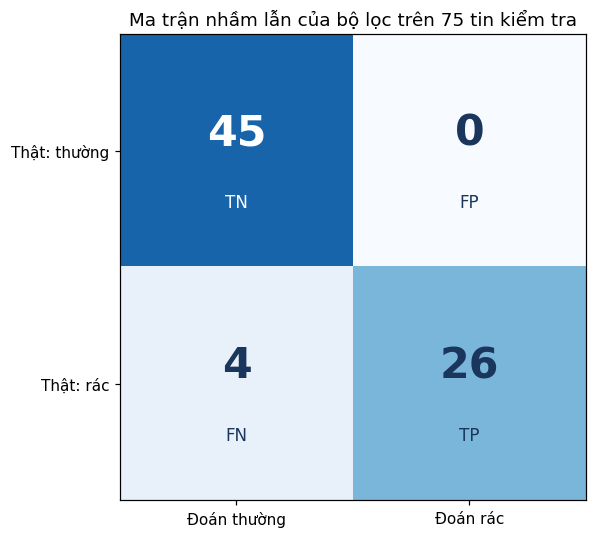

In [7]:
# Hình 2: ma trận nhầm lẫn của bộ lọc trên 75 tin nhắn kiểm tra
ma_tran = confusion_matrix(y_test, y_pred)
ten_o = [["TN", "FP"], ["FN", "TP"]]

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.imshow(ma_tran, cmap="Blues", vmin=0, vmax=ma_tran.max() * 1.25)
for hang in range(2):
    for cot in range(2):
        mau_chu = "white" if ma_tran[hang, cot] > ma_tran.max() * 0.6 else "#1a365d"
        ax.text(cot, hang - 0.08, str(ma_tran[hang, cot]), ha="center", va="center",
                fontsize=28, fontweight="bold", color=mau_chu)
        ax.text(cot, hang + 0.22, ten_o[hang][cot], ha="center", va="center",
                fontsize=11, color=mau_chu)
ax.set_xticks([0, 1], ["Đoán thường", "Đoán rác"])
ax.set_yticks([0, 1], ["Thật: thường", "Thật: rác"])
ax.grid(False)
ax.set_title(f"Ma trận nhầm lẫn của bộ lọc trên {len(y_test)} tin kiểm tra")
plt.tight_layout()
luu_hinh("hinh2_ma_tran_nham_lan_bo_loc.png")

**Đọc kết quả:** accuracy đạt **0.9467**, nhưng con số đáng chú ý hơn nằm ở hai cột còn lại.

- **Precision = 1.0000.** Trong tất cả những tin mà bộ lọc gắn nhãn rác, không có tin nào là thư thật.
  Nghĩa là FP bằng 0.
- **Recall = 0.8667.** Trong 30 tin rác của tập kiểm tra, bộ lọc bắt được 26 tin và để lọt 4 tin.

> **Vì sao kết quả này đáng mừng:** nhớ lại bài 2, phần chọn ngưỡng. Với bộ lọc thư rác, sai kiểu FP
> nghĩa là **xoá nhầm một lá thư thật** và lá thư đó mất luôn — hậu quả rất nặng. Sai kiểu FN chỉ là để
> lọt một tin rác vào hộp thư, người dùng tự xoá tay. Bộ lọc này để lọt 4 tin rác nhưng **không xoá
> nhầm lá thư nào** — đúng là kiểu sai rẻ tiền mà ta muốn, và nó quan trọng hơn con số accuracy.

Phần cuối thử bộ lọc trên ba tin tự gõ: tin quảng cáo nhận xác suất **0.9992**, hai tin thường nhận
**0.0983** và **0.0719**. Mô hình rất dứt khoát — vừa là ưu điểm, vừa là điều phải cảnh giác.

> ⚠️ **Xác suất của Naive Bayes thường quá tự tin.** Vì giả định ngây thơ sai, mô hình **đếm cùng một
> bằng chứng nhiều lần** khi các từ đi kèm nhau, nên con số xác suất bị đẩy sát 0 hoặc sát 1. Dùng nó để
> *chọn lớp* thì tốt; dùng nó làm *xác suất thật* để đặt ngưỡng như bài 2 thì phải rất cẩn thận —
> 0.9992 ở đây không có nghĩa là mô hình chắc chắn tới 99.92 phần trăm.

Ô dưới soi kỹ hơn ba tin tự gõ: chúng được gõ **không dấu**, trong khi từ điển học từ kho tin **có
dấu**. Vậy thật ra bộ lọc nhìn thấy được những từ nào?

In [8]:
# Làm thêm: mỗi tin tự gõ còn lại những từ nào sau khi đi qua từ điển 40 từ?
for tin, dong in zip(tin_moi, vec.inverse_transform(X_moi)):
    so_tu = len(tin.split())
    print(f"{tin}")
    print(f"   -> {so_tu} tu, bo loc chi nhin thay {len(dong)} tu: {list(dong)}")

trung thuong khuyen mai nhanh tay click ngay
   -> 8 tu, bo loc chi nhin thay 5 tu: ['click', 'mai', 'ngay', 'nhanh', 'tay']
hop nhom bao cao chieu mai phong 305
   -> 8 tu, bo loc chi nhin thay 1 tu: ['mai']
ban gui giup em tai lieu bai tap nhe
   -> 9 tu, bo loc chi nhin thay 1 tu: ['em']


Kết quả rất đáng suy nghĩ: tin quảng cáo có 8 từ nhưng bộ lọc chỉ nhận ra **5 từ** — bốn từ rác vốn
không dấu sẵn trong từ điển (`nhanh`, `tay`, `click`, `ngay`), cộng với `mai` của chữ *khuyen mai* gõ
không dấu, mà bộ lọc lại hiểu là `mai` trong *chiều mai* — một từ của tin **thường**. Dù vậy bốn từ rác vẫn
đủ đẩy xác suất lên 0.9992. Hai tin thường
còn tệ hơn: mỗi tin chỉ lọt được **đúng một từ** (`mai`, `em`) vào mắt bộ lọc, phần còn lại bị bỏ qua
hoàn toàn. Hai con số 0.0983 và 0.0719 vì vậy gần như chỉ phản ánh tiên nghiệm cộng với một từ duy nhất.

Đây là ví dụ sống cho lời cảnh báo ở Bước 4: **từ chưa từng có trong kho huấn luyện thì không có trong
từ điển, và bộ lọc coi như nó không tồn tại.**

---
## Bước 4 — Vấn đề số không và cách làm trơn *(Mục 5, `d4_lam_tron.py`)*

### Một số không đủ sức khoá cả phép nhân

Công thức Naive Bayes là một phép **nhân** dài. Trong một phép nhân, chỉ cần một thừa số bằng 0 là cả
tích bằng 0, bất kể các thừa số còn lại lớn tới đâu. Chuyện đó xảy ra khi có một từ **chưa từng xuất
hiện trong một lớp** nào đó của tập huấn luyện: số đếm bằng 0, nên xác suất của từ đó cũng bằng 0.

> ⚠️ **Hậu quả:** một tin nhắn chứa từ *trúng* và từ *thưởng* — hai dấu hiệu rác rất mạnh — vẫn có thể
> bị xếp vào lớp thường chỉ vì nó cũng chứa một từ mà lớp rác chưa từng gặp. Mô hình bị **một từ duy
> nhất khoá miệng**.

### Làm trơn Laplace

Cách chữa đơn giản tới bất ngờ: cộng thêm một lượng nhỏ vào mọi số đếm.

$$\mathbb{P}(\text{từ } j \mid \text{lớp } k) = \frac{\text{đếm}_{jk} + \alpha}{\text{tổng}_k + \alpha V}$$

$V$ là số từ trong từ điển, còn $\alpha$ thường chọn bằng 1. Coi như mỗi từ đã xuất hiện sẵn $\alpha$ lần
ở mọi lớp trước khi ta nhìn vào dữ liệu, nhờ vậy không xác suất nào bằng 0 nữa. Mẫu số phải cộng
$\alpha V$ để tổng các xác suất vẫn bằng 1.

### Tự cài đặt để thấy tận mắt

Thư viện đã làm trơn sẵn với `alpha=1.0`, nên nếu chỉ gọi thư viện thì không bao giờ thấy chỗ hỏng.
Ô dưới tự cài Naive Bayes trên một kho tí hon gồm sáu tin nhắn, để bật hoặc tắt làm trơn tuỳ ý.

In [9]:
"""Bước 4: tự cài Naive Bayes trên một kho nhỏ để thấy vấn đề số không.

Đoạn này cố ý KHÔNG dùng scikit-learn, vì thư viện đã làm trơn sẵn nên
không nhìn thấy chỗ hỏng.
"""

from collections import Counter

# Kho tin nhắn tí hon, viết thẳng vào mã cho dễ theo dõi
kho = [
    ("trung thuong ngay", 1),
    ("khuyen mai giam gia", 1),
    ("trung thuong click", 1),
    ("hop nhom chieu mai", 0),
    ("bai tap nhom nop mai", 0),
    ("thay gui tai lieu", 0),
]

tu_dien = sorted({t for cau, _ in kho for t in cau.split()})
V = len(tu_dien)
print(f"Tu dien co {V} tu:")
# In thành nhiều dòng, mỗi dòng 9 từ
for i in range(0, V, 9):
    print("  " + " ".join(tu_dien[i:i + 9]))
print()

# Đếm số lần mỗi từ xuất hiện trong từng lớp
dem = {0: Counter(), 1: Counter()}
tong = {0: 0, 1: 0}
for cau, nhan in kho:
    for t in cau.split():
        dem[nhan][t] += 1
        tong[nhan] += 1

print("So lan xuat hien cua tung tu")
print(f"  {'tu':12s} {'rac':>5s} {'thuong':>7s}")
for t in tu_dien:
    print(f"  {t:12s} {dem[1][t]:5d} {dem[0][t]:7d}")
print()


def xac_suat(tu, nhan, alpha):
    """P(tu | nhan) co lam tron Laplace voi he so alpha."""
    return (dem[nhan][tu] + alpha) / (tong[nhan] + alpha * V)


def diem(cau, nhan, alpha):
    """Tich cua xac suat tien nghiem va cac xac suat tu."""
    p = 0.5          # hai lớp cân bằng nên tiên nghiệm bằng nhau
    for t in cau.split():
        if t in tu_dien:
            p *= xac_suat(t, nhan, alpha)
    return p


cau_thu = "trung thuong bai tap"
print(f"Tin nhan thu: \"{cau_thu}\"")
print("Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.")
print()

for alpha in [0.0, 1.0]:
    d_rac = diem(cau_thu, 1, alpha)
    d_thuong = diem(cau_thu, 0, alpha)
    ket = "rac" if d_rac > d_thuong else "thuong"
    print(f"alpha = {alpha}")
    print(f"  diem lop rac    = {d_rac:.10f}")
    print(f"  diem lop thuong = {d_thuong:.10f}")
    print(f"  ket luan        = {ket}")
    print()

print("Khong lam tron, CA HAI diem deu bang 0 nen mo hinh te liet.")
print("Lop rac bang 0 vi tu 'bai' chua tung xuat hien o lop rac.")
print("Lop thuong bang 0 vi tu 'trung' chua tung xuat hien o lop thuong.")
print("Co lam tron, diem lop rac lon hon va mo hinh ket luan dung.")

Tu dien co 18 tu:
  bai chieu click gia giam gui hop khuyen lieu
  mai ngay nhom nop tai tap thay thuong trung

So lan xuat hien cua tung tu
  tu             rac  thuong
  bai              0       1
  chieu            0       1
  click            1       0
  gia              1       0
  giam             1       0
  gui              0       1
  hop              0       1
  khuyen           1       0
  lieu             0       1
  mai              1       2
  ngay             1       0
  nhom             0       2
  nop              0       1
  tai              0       1
  tap              0       1
  thay             0       1
  thuong           2       0
  trung            2       0

Tin nhan thu: "trung thuong bai tap"
Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.

alpha = 0.0
  diem lop rac    = 0.0000000000
  diem lop thuong = 0.0000000000
  ket luan        = thuong

alpha = 1.0
  diem lop rac    = 0.0000073212
  diem lop thuong = 0.0000021656
  ket luan        = rac


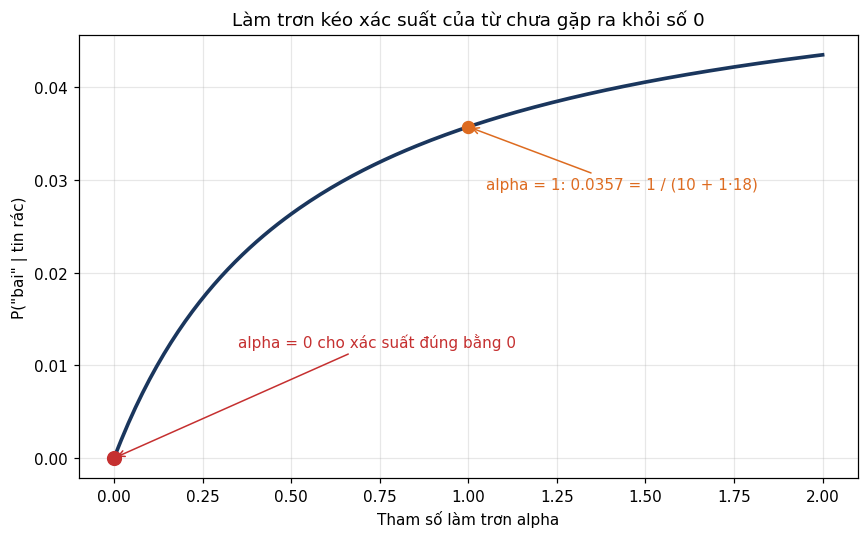

In [10]:
# Hình 3: xác suất của một từ chưa từng gặp ở lớp rác, theo tham số làm trơn
luoi_alpha = np.linspace(0, 2, 200)
p_bai_rac = [xac_suat("bai", 1, a) for a in luoi_alpha]

plt.figure()
plt.plot(luoi_alpha, p_bai_rac, color=MAU_THUONG, linewidth=2.4)
plt.scatter([0], [0], s=80, color=MAU_RAC, zorder=5)
plt.annotate("alpha = 0 cho xác suất đúng bằng 0", xy=(0, 0), xytext=(0.35, 0.012),
             color=MAU_RAC, arrowprops=dict(arrowstyle="->", color=MAU_RAC))
plt.scatter([1], [xac_suat("bai", 1, 1.0)], s=60, color="#dd6b20", zorder=5)
plt.annotate(f"alpha = 1: {xac_suat('bai', 1, 1.0):.4f} = 1 / ({tong[1]} + 1·{V})",
             xy=(1, xac_suat("bai", 1, 1.0)), xytext=(1.05, 0.029), color="#dd6b20",
             arrowprops=dict(arrowstyle="->", color="#dd6b20"))
plt.xlabel("Tham số làm trơn alpha")
plt.ylabel('P("bai" | tin rác)')
plt.title("Làm trơn kéo xác suất của từ chưa gặp ra khỏi số 0")
plt.tight_layout()
luu_hinh("hinh3_lam_tron_laplace.png")

**Đọc kết quả:** tin nhắn thử là *trung thuong bai tap*, một tin rác có lẫn hai từ của lớp thường.

- Khi $\alpha = 0$, kết quả còn tệ hơn dự đoán: **cả hai điểm đều bằng 0**. Lớp rác bằng 0 vì từ `bai`
  chưa từng xuất hiện ở lớp rác; lớp thường bằng 0 vì từ `trung` chưa từng xuất hiện ở lớp thường. Mô
  hình tê liệt hoàn toàn — `d_rac > d_thuong` sai nên nó *rơi* vào nhánh "thuong", tức là **chọn bừa**.
- Khi $\alpha = 1$, điểm lớp rác bằng **0.0000073212** còn lớp thường bằng **0.0000021656**. Cả hai đều
  rất nhỏ nhưng khác 0, nên so sánh được, và mô hình kết luận đúng là tin rác.

> **Vì sao hai con số nhỏ tới vậy:** vì chúng là tích của bốn xác suất, mỗi cái cỡ vài phần trăm. Với
> tin nhắn dài hơn, tích còn nhỏ nữa và máy tính sẽ làm tròn thành đúng số 0 — hiện tượng **tràn dưới**
> (*underflow*). Cách chữa là lấy loga rồi **cộng** thay vì nhân:
> $$\log\Big(\mathbb{P}(y)\prod_j \mathbb{P}(x_j \mid y)\Big) = \log \mathbb{P}(y) + \sum_j \log \mathbb{P}(x_j \mid y)$$
> Hàm loga đồng biến nên thứ tự hai lớp không đổi. Scikit-learn làm sẵn mẹo này, và thuộc tính
> `feature_log_prob_` chính là các giá trị loga đó. Ô dưới cho thấy tràn dưới xảy ra thật.

In [11]:
# Làm thêm: tận mắt thấy tràn dưới với một "tin nhắn" 300 từ, mỗi từ xác suất 0.05
xac_suat_moi_tu = 0.05
for so_tu in [10, 100, 200, 250, 300]:
    tich = 1.0
    for _ in range(so_tu):
        tich *= xac_suat_moi_tu
    tong_loga = so_tu * np.log(xac_suat_moi_tu)
    print(f"{so_tu:4d} tu: nhan truc tiep = {tich:.3e}   |   cong loga = {tong_loga:9.2f}")

  10 tu: nhan truc tiep = 9.766e-14   |   cong loga =    -29.96
 100 tu: nhan truc tiep = 7.889e-131   |   cong loga =   -299.57
 200 tu: nhan truc tiep = 6.223e-261   |   cong loga =   -599.15
 250 tu: nhan truc tiep = 0.000e+00   |   cong loga =   -748.93
 300 tu: nhan truc tiep = 0.000e+00   |   cong loga =   -898.72


Tới khoảng 250 từ, phép nhân trực tiếp đã rơi về **đúng 0.0** (số thực của máy tính không biểu diễn
được số nhỏ hơn cỡ $10^{-324}$), còn tổng loga vẫn là một con số bình thường. Hai lớp cùng bằng 0 thì
lại quay về cảnh tê liệt ở trên.

> ⚠️ **Làm trơn không cứu được từ hoàn toàn mới.** Làm trơn chỉ xử lý được từ *có trong từ điển nhưng
> chưa gặp ở một lớp*. Một từ chưa từng xuất hiện trong kho huấn luyện thì không có trong từ điển, nên
> `CountVectorizer` bỏ qua nó hoàn toàn — đúng như ba tin không dấu ở Bước 3. Đó là lý do bộ lọc thư rác
> phải được huấn luyện lại định kỳ khi kẻ gửi rác đổi từ ngữ. Hiện tượng dữ liệu đổi theo thời gian gọi
> là **trôi dữ liệu** (*data drift*).

---
## Bước 5 — Naive Bayes cho số liệu liên tục *(Mục 6, `d5_gaussian.py`)*

### Đếm không còn dùng được

Đếm số lần một từ xuất hiện thì dễ, nhưng số giờ ôn tập là một số thực. Không ai đếm được *số lần giá
trị 12.5 xuất hiện*, vì gần như mỗi sinh viên có một con số khác nhau.

Cách xử lý là giả định **mỗi lớp có một đường chuông riêng**, tức một phân phối chuẩn. Huấn luyện khi
đó chỉ gồm hai phép tính cho mỗi lớp và mỗi đặc trưng: **tính trung bình** và **tính độ lệch chuẩn**.

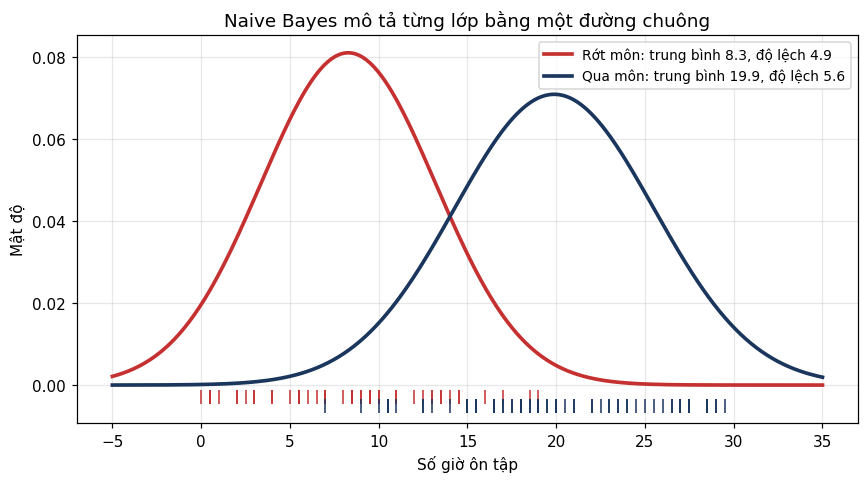

In [12]:
# Hình 4: hai đường chuông mô tả số giờ ôn tập của nhóm rớt và nhóm qua
from sklearn.naive_bayes import GaussianNB

sinh_vien = pd.read_csv(DUONG_DAN_SV)
gnb_mot_bien = GaussianNB().fit(sinh_vien[["gio_on"]], sinh_vien["qua_mon"])


def mat_do_chuan(x, trung_binh, do_lech):
    """Mat do cua phan phoi chuan tai x."""
    return np.exp(-0.5 * ((x - trung_binh) / do_lech) ** 2) / (do_lech * np.sqrt(2 * np.pi))


luoi_gio = np.linspace(-5, 35, 400)
plt.figure(figsize=(8, 4.5))
for lop, ten, mau in [(0, "Rớt môn", MAU_RAC), (1, "Qua môn", MAU_THUONG)]:
    tb = gnb_mot_bien.theta_[lop, 0]
    dl = np.sqrt(gnb_mot_bien.var_[lop, 0])
    plt.plot(luoi_gio, mat_do_chuan(luoi_gio, tb, dl), color=mau, linewidth=2.4,
             label=f"{ten}: trung bình {tb:.1f}, độ lệch {dl:.1f}")
    gio_lop = sinh_vien.loc[sinh_vien["qua_mon"] == lop, "gio_on"]
    plt.plot(gio_lop, np.full(len(gio_lop), -0.003 - 0.002 * lop), "|", color=mau, markersize=9)
plt.xlabel("Số giờ ôn tập")
plt.ylabel("Mật độ")
plt.title("Naive Bayes mô tả từng lớp bằng một đường chuông")
plt.legend(loc="upper right", fontsize=9)
plt.tight_layout()
luu_hinh("hinh4_hai_duong_chuong.png")

Các vạch nhỏ ở đáy là từng sinh viên thật. Hai đường chuông chính là toàn bộ những gì Naive Bayes
"nhớ" về số giờ ôn: nhóm rớt tụ quanh 8.3 giờ, nhóm qua tụ quanh 19.9 giờ.

> **Biến thể nào cho kiểu dữ liệu nào:**
> - `MultinomialNB` cho dữ liệu **đếm**, ví dụ số lần một từ xuất hiện.
> - `GaussianNB` cho dữ liệu **liên tục**, ví dụ chiều cao, cân nặng, số giờ.
> - `BernoulliNB` cho dữ liệu **có hoặc không**, ví dụ từ đó có mặt hay vắng mặt.
>
> Chọn sai biến thể thì chương trình vẫn chạy và vẫn in ra một con số accuracy, nên đây là kiểu **lỗi
> im lặng** rất nguy hiểm (Bài tập 5 sẽ thử).

### So với hồi quy logistic trên cùng dữ liệu

In [13]:
"""Bước 5: Naive Bayes cho số liệu liên tục, đặt cạnh hồi quy logistic."""

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB

df = pd.read_csv(DUONG_DAN_SV)
X = df[["gio_on", "diem_giua_ky"]]
y = df["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

# Hai mô hình, cùng dữ liệu, cùng cách chia, nên so sánh mới công bằng
for ten, mo_hinh in [("Naive Bayes     ", GaussianNB()),
                     ("Hoi quy logistic", LogisticRegression())]:
    mo_hinh.fit(X_train, y_train)
    acc = accuracy_score(y_test, mo_hinh.predict(X_test))
    print(f"{ten}: accuracy = {acc:.4f}")
print()

gnb = GaussianNB().fit(X_train, y_train)

# theta_ la trung binh, var_ la phuong sai, moi dong mot lop
print("Nhung gi Naive Bayes hoc duoc")
print(f"  {'':16s} {'gio_on':>10s} {'diem_giua_ky':>14s}")
for i, ten_lop in enumerate(["Lop 0 (rot) ", "Lop 1 (qua) "]):
    tb = gnb.theta_[i]
    dl = gnb.var_[i] ** 0.5
    print(f"  {ten_lop} trung binh {tb[0]:10.2f} {tb[1]:14.2f}")
    print(f"  {'':12s} do lech   {dl[0]:10.2f} {dl[1]:14.2f}")
print()

ty_le = ", ".join(f"{float(v):.4f}" for v in gnb.class_prior_)
print(f"Ty le tung lop trong tap hoc: {ty_le}")
print()

# Dự đoán cho vài sinh viên giả định
ban_moi = pd.DataFrame({"gio_on": [5, 13, 20, 28],
                        "diem_giua_ky": [4.0, 6.0, 7.0, 9.0]})
p = gnb.predict_proba(ban_moi)[:, 1]
print("Du doan cho bon ban moi:")
print(f"  {'gio on':>8s} {'diem GK':>9s} {'P(qua mon)':>12s}")
for (_, r), pi in zip(ban_moi.iterrows(), p):
    print(f"  {r.gio_on:8.0f} {r.diem_giua_ky:9.1f} {pi:12.4f}")

Naive Bayes     : accuracy = 0.9000
Hoi quy logistic: accuracy = 0.9000

Nhung gi Naive Bayes hoc duoc
                       gio_on   diem_giua_ky
  Lop 0 (rot)  trung binh       8.18           3.99
               do lech         5.29           1.92
  Lop 1 (qua)  trung binh      20.03           6.70
               do lech         5.81           1.50

Ty le tung lop trong tap hoc: 0.4111, 0.5889

Du doan cho bon ban moi:
    gio on   diem GK   P(qua mon)
         5       4.0       0.0137
        13       6.0       0.6550
        20       7.0       0.9855
        28       9.0       0.9999


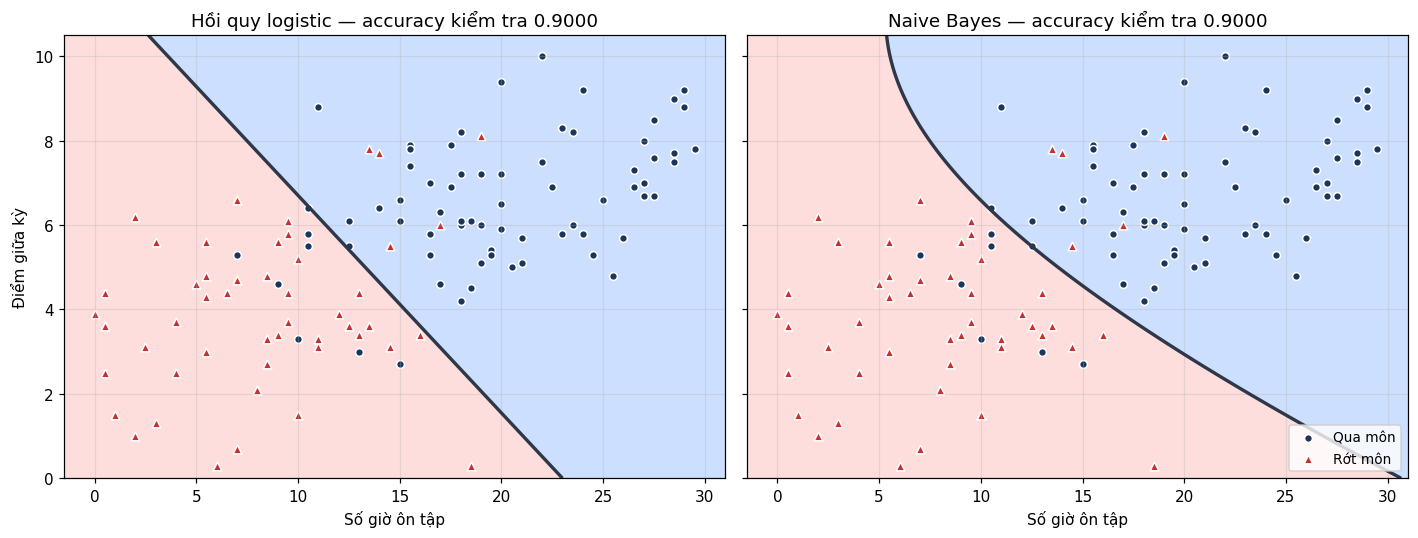

In [14]:
# Hình 5: biên quyết định của hai mô hình trên cùng bộ dữ liệu
logistic = LogisticRegression().fit(X_train, y_train)

luoi_x1, luoi_x2 = np.meshgrid(np.linspace(-1.5, 31, 300), np.linspace(0, 10.5, 300))
luoi_diem = pd.DataFrame({"gio_on": luoi_x1.ravel(), "diem_giua_ky": luoi_x2.ravel()})
nhom_qua = df[df["qua_mon"] == 1]
nhom_rot = df[df["qua_mon"] == 0]

fig, cac_truc = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (ten, mh) in zip(cac_truc, [("Hồi quy logistic", logistic), ("Naive Bayes", gnb)]):
    xac_suat_luoi = mh.predict_proba(luoi_diem)[:, 1].reshape(luoi_x1.shape)
    ax.contourf(luoi_x1, luoi_x2, xac_suat_luoi >= 0.5, levels=[-0.5, 0.5, 1.5],
                colors=["#fed7d7", "#c3dafe"], alpha=0.85)
    ax.contour(luoi_x1, luoi_x2, xac_suat_luoi, levels=[0.5], colors="#2d3748", linewidths=2.2)
    ax.scatter(nhom_qua["gio_on"], nhom_qua["diem_giua_ky"], s=26, marker="o",
               color=MAU_THUONG, edgecolor="white", label="Qua môn")
    ax.scatter(nhom_rot["gio_on"], nhom_rot["diem_giua_ky"], s=32, marker="^",
               color=MAU_RAC, edgecolor="white", label="Rớt môn")
    acc = accuracy_score(y_test, mh.predict(X_test))
    ax.set_title(f"{ten} — accuracy kiểm tra {acc:.4f}")
    ax.set_xlabel("Số giờ ôn tập")
    ax.set_xlim(-1.5, 31)
    ax.set_ylim(0, 10.5)
cac_truc[0].set_ylabel("Điểm giữa kỳ")
cac_truc[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
luu_hinh("hinh5_bien_quyet_dinh_hai_mo_hinh.png")

**Đọc kết quả:** hai mô hình cho accuracy bằng nhau, cùng **0.9000**. Điều này không có nghĩa chúng là
một, nó chỉ nói rằng trên bộ dữ liệu nhỏ này cả hai đều hợp. Hình 5 cho thấy biên của hồi quy logistic
là một **đường thẳng** (đúng như bài 2), còn biên của Naive Bayes là một **đường cong** — vì hai lớp có
độ lệch chuẩn khác nhau nên hai đường chuông giao nhau theo một đường cong. Trên vùng có dữ liệu, hai
đường gần như trùng nhau.

Phần `theta_` và `var_` cho thấy Naive Bayes đã học được gì: nhóm rớt có số giờ ôn trung bình **8.18
giờ** và điểm giữa kỳ trung bình **3.99**; nhóm qua có **20.03 giờ** và **6.70 điểm**. Hai nhóm cách
nhau rõ ở cả hai đặc trưng, nên bài toán này dễ với mọi mô hình. Tiên nghiệm 0.4111 / 0.5889 chính là
tỷ lệ 37 rớt / 53 qua trong 90 bạn của tập học.

> **Điểm khác nhau đáng nhớ giữa hai mô hình:** hồi quy logistic học **ranh giới** và không quan tâm mỗi
> lớp trông ra sao. Naive Bayes học **hình dạng từng lớp** rồi mới suy ra ranh giới. Vì vậy Naive Bayes
> cho ta thêm thông tin: nó nói được nhóm rớt ôn trung bình bao nhiêu giờ — hồi quy logistic không trả
> lời được câu đó.

### Chỗ hai mô hình khác nhau rõ rệt *(Hình 6)*

Trên bài lọc tin rác, nơi có tới 40 đặc trưng, sự khác nhau lộ rất rõ khi **dữ liệu huấn luyện ít**.
Ô dưới lấy ngẫu nhiên $n$ tin trong 225 tin của tập học (mỗi lần bốc phải có đủ cả hai lớp), huấn luyện
cả hai mô hình, chấm trên đúng 75 tin kiểm tra của Bước 3, lặp lại 100 lần rồi lấy trung bình.

 So tin hoc   Naive Bayes   Hoi quy logistic   Chenh lech
      10        0.9115          0.7841          +0.1273
      20        0.9357          0.8853          +0.0504
      30        0.9404          0.9137          +0.0267
      50        0.9445          0.9240          +0.0205
      80        0.9457          0.9257          +0.0200
     150        0.9467          0.9272          +0.0195
     225        0.9467          0.9200          +0.0267


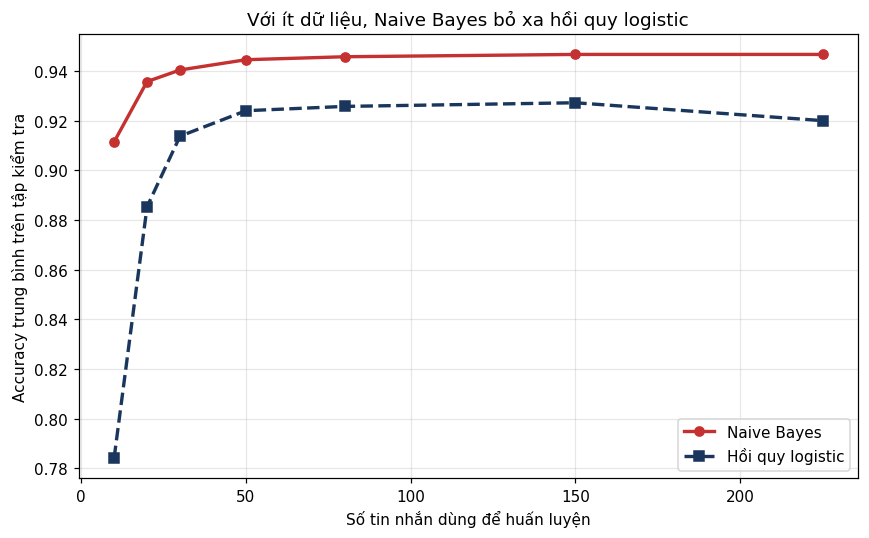

In [15]:
"""Hình 6: accuracy trung bình theo số tin nhắn dùng để huấn luyện."""

df_tin = pd.read_csv(DUONG_DAN_TIN)
vec_tin = CountVectorizer(token_pattern=r"(?u)\S+")
X_tin = vec_tin.fit_transform(df_tin["noi_dung"])
y_tin = df_tin["la_rac"].to_numpy()
X_hoc_tin, X_kt_tin, y_hoc_tin, y_kt_tin = train_test_split(
    X_tin, y_tin, test_size=0.25, random_state=17, stratify=y_tin
)

SO_LAN_LAP = 100
cac_co_mau = [10, 20, 30, 50, 80, 150, 225]
bo_sinh_so = np.random.RandomState(17)
acc_nb, acc_lr = [], []

for co_mau in cac_co_mau:
    diem_nb, diem_lr = [], []
    so_lan = 1 if co_mau == len(y_hoc_tin) else SO_LAN_LAP   # dùng cả 225 tin thì chỉ có một cách
    for _ in range(so_lan):
        while True:
            chi_so = bo_sinh_so.choice(len(y_hoc_tin), co_mau, replace=False)
            if len(set(y_hoc_tin[chi_so])) == 2:             # phải có đủ cả rác lẫn thường
                break
        X_con, y_con = X_hoc_tin[chi_so], y_hoc_tin[chi_so]
        diem_nb.append(accuracy_score(y_kt_tin, MultinomialNB().fit(X_con, y_con).predict(X_kt_tin)))
        diem_lr.append(accuracy_score(y_kt_tin, LogisticRegression().fit(X_con, y_con).predict(X_kt_tin)))
    acc_nb.append(np.mean(diem_nb))
    acc_lr.append(np.mean(diem_lr))

print(" So tin hoc   Naive Bayes   Hoi quy logistic   Chenh lech")
for co_mau, a_nb, a_lr in zip(cac_co_mau, acc_nb, acc_lr):
    print(f"   {co_mau:5d}        {a_nb:.4f}          {a_lr:.4f}          {a_nb - a_lr:+.4f}")

plt.figure()
plt.plot(cac_co_mau, acc_nb, "-o", color=MAU_RAC, linewidth=2.2, label="Naive Bayes")
plt.plot(cac_co_mau, acc_lr, "--s", color=MAU_THUONG, linewidth=2.2, label="Hồi quy logistic")
plt.xlabel("Số tin nhắn dùng để huấn luyện")
plt.ylabel("Accuracy trung bình trên tập kiểm tra")
plt.title("Với ít dữ liệu, Naive Bayes bỏ xa hồi quy logistic")
plt.legend(loc="lower right")
plt.tight_layout()
luu_hinh("hinh6_duong_hoc_theo_co_mau.png")

**Đọc kết quả:** với chỉ **10 tin** huấn luyện, Naive Bayes đã đạt khoảng **0.91** còn hồi quy logistic
chỉ khoảng **0.78**. Khi dùng đủ **225 tin**, khoảng cách thu hẹp còn **0.9467 so với 0.9200**.

*(Hai con số ở mốc 10 tin phụ thuộc vào các lần bốc ngẫu nhiên, nên lệch vài phần nghìn so với
0.9072 / 0.7808 trong tài liệu; mốc 225 tin không có ngẫu nhiên nên khớp đúng tài liệu.)*

> **Vì sao Naive Bayes trụ tốt khi dữ liệu ít:** Naive Bayes chỉ cần ước lượng 40 con số cho mỗi lớp,
> mỗi con số lấy từ một phép đếm đơn giản. Hồi quy logistic phải dò 40 trọng số **cùng lúc** sao cho
> chúng phối hợp với nhau, và với mười mẫu thì không đủ thông tin để dò. Giả định ngây thơ tuy sai nhưng
> đóng vai trò một **cái khung đỡ**, giúp mô hình đứng vững khi dữ liệu còn mỏng — một ví dụ đẹp cho
> thấy một giả định sai vẫn có thể có ích.

**Chọn mô hình nào cho tình huống nào** *(Bảng 5)*:

| Tình huống | Naive Bayes | Hồi quy logistic |
|---|---|---|
| Dữ liệu ít, đặc trưng nhiều | Rất hợp | Dễ học vẹt |
| Dữ liệu nhiều | Thường thua một chút | Thường nhỉnh hơn |
| Đặc trưng liên quan chặt | Xác suất bị thổi phồng | Xử lý tốt hơn |
| Cần huấn luyện thật nhanh | Chỉ đếm một lượt | Phải dò nhiều vòng |
| Cần xác suất đáng tin | Không nên tin | Đáng tin hơn |

> 💡 **Lời khuyên dùng được ngay:** với mọi bài phân loại mới, hãy chạy Naive Bayes trước tiên vì nó
> nhanh và gần như không có tham số nào cần chỉnh. Lấy kết quả đó làm **mốc đối chứng**, rồi mới thử
> những mô hình phức tạp hơn. Mô hình nào không vượt được mốc này thì chưa đáng dùng.

---
# Phần B — Bài tập *(Mục 7)*

**Tiêu chí chấm:** mã chạy được không lỗi, kết quả in ra đúng, có nhận xét bằng lời ở những bài yêu
cầu, tên biến đặt có nghĩa. Riêng **bài 4 và bài 6 chấm nặng phần giải thích**, vì đó là chỗ kiểm tra
sinh viên có thật sự hiểu cơ chế hay chỉ gọi hàm.

> 📌 **Lưu ý khi nộp bài:** thầy yêu cầu mỗi bài là **một tệp `.py` riêng** trong thư mục
> `baitap03` (`bai1.py` … `bai6.py`), chạy bằng `python baitap03/bai1.py` từ thư mục gốc.
> Notebook này dùng để làm và kiểm tra kết quả; khi nộp thì chép nội dung từng ô mã sang tệp `.py`
> tương ứng, thêm các dòng `import` ở đầu và để đường dẫn là `data/tin_nhan.csv` (hoặc
> `data/sinh_vien.csv` cho bài 5).

## Bài tập 1 — Bayes với ba nguyên nhân

Một lớp có ba nhóm sinh viên: **50%** học đều, **30%** học dồn, **20%** ít học. Tỷ lệ qua môn của ba
nhóm lần lượt là **0.95**, **0.70** và **0.30**. Gặp một bạn đã qua môn. Tính xác suất bạn đó thuộc từng
nhóm; ba con số cộng lại phải bằng 1, dùng điều đó để tự kiểm tra.

Gợi ý của đề: mở rộng hàm `bayes` ở Bước 1 cho ba nhánh thay vì hai. Mẫu số giờ là tổng của **ba**
nhánh (công thức xác suất toàn phần):

$$\mathbb{P}(\text{nhóm } i \mid \text{qua}) = \frac{\mathbb{P}(\text{qua} \mid \text{nhóm } i)\,\mathbb{P}(\text{nhóm } i)}{\sum_{k} \mathbb{P}(\text{qua} \mid \text{nhóm } k)\,\mathbb{P}(\text{nhóm } k)}$$

In [16]:
"""Bai 1: dinh ly Bayes voi ba nguyen nhan (ba nhom sinh vien)."""


def bayes_nhieu_nhanh(cac_tien_nghiem, cac_kha_nang):
    """Tra ve danh sach hau nghiem, mot gia tri cho moi nhanh.

    cac_tien_nghiem : P(nhom i), tong phai bang 1
    cac_kha_nang    : P(bang chung | nhom i)
    """
    cac_tu_so = [tien * kha for tien, kha in zip(cac_tien_nghiem, cac_kha_nang)]
    bang_chung = sum(cac_tu_so)            # xac suat toan phan P(qua mon)
    return [tu_so / bang_chung for tu_so in cac_tu_so], bang_chung


ten_nhom = ["hoc deu", "hoc don", "it hoc"]
ty_le_nhom = [0.50, 0.30, 0.20]
ty_le_qua_theo_nhom = [0.95, 0.70, 0.30]

hau_nghiem, xac_suat_qua = bayes_nhieu_nhanh(ty_le_nhom, ty_le_qua_theo_nhom)

print(f"Xac suat qua mon chung P(qua) = "
      + " + ".join(f"{t}*{k}" for t, k in zip(ty_le_nhom, ty_le_qua_theo_nhom))
      + f" = {xac_suat_qua:.4f}")
print()
print(f"{'Nhom':10s} {'Tien nghiem':>12s} {'P(qua|nhom)':>12s} {'P(nhom|qua)':>12s}")
for ten, tien, kha, hau in zip(ten_nhom, ty_le_nhom, ty_le_qua_theo_nhom, hau_nghiem):
    print(f"{ten:10s} {tien:12.2f} {kha:12.2f} {hau:12.4f}")
print()
print(f"Tu kiem tra: tong ba hau nghiem = {sum(hau_nghiem):.4f}")
print()

# Kiem lai bang cach dem tren 1000 sinh vien
print("Kiem lai bang cach dem tren 1000 sinh vien:")
so_qua_tung_nhom = [1000 * tien * kha for tien, kha in zip(ty_le_nhom, ty_le_qua_theo_nhom)]
for ten, tien, so_qua in zip(ten_nhom, ty_le_nhom, so_qua_tung_nhom):
    print(f"  {ten:8s}: {1000 * tien:4.0f} ban, {so_qua:5.0f} ban qua mon")
tong_qua = sum(so_qua_tung_nhom)
print(f"  Tong so ban qua mon: {tong_qua:.0f}")
for ten, so_qua in zip(ten_nhom, so_qua_tung_nhom):
    print(f"  P({ten} | qua) = {so_qua:.0f} / {tong_qua:.0f} = {so_qua / tong_qua:.4f}")

Xac suat qua mon chung P(qua) = 0.5*0.95 + 0.3*0.7 + 0.2*0.3 = 0.7450

Nhom        Tien nghiem  P(qua|nhom)  P(nhom|qua)
hoc deu            0.50         0.95       0.6376
hoc don            0.30         0.70       0.2819
it hoc             0.20         0.30       0.0805

Tu kiem tra: tong ba hau nghiem = 1.0000

Kiem lai bang cach dem tren 1000 sinh vien:
  hoc deu :  500 ban,   475 ban qua mon
  hoc don :  300 ban,   210 ban qua mon
  it hoc  :  200 ban,    60 ban qua mon
  Tong so ban qua mon: 745
  P(hoc deu | qua) = 475 / 745 = 0.6376
  P(hoc don | qua) = 210 / 745 = 0.2819
  P(it hoc | qua) = 60 / 745 = 0.0805


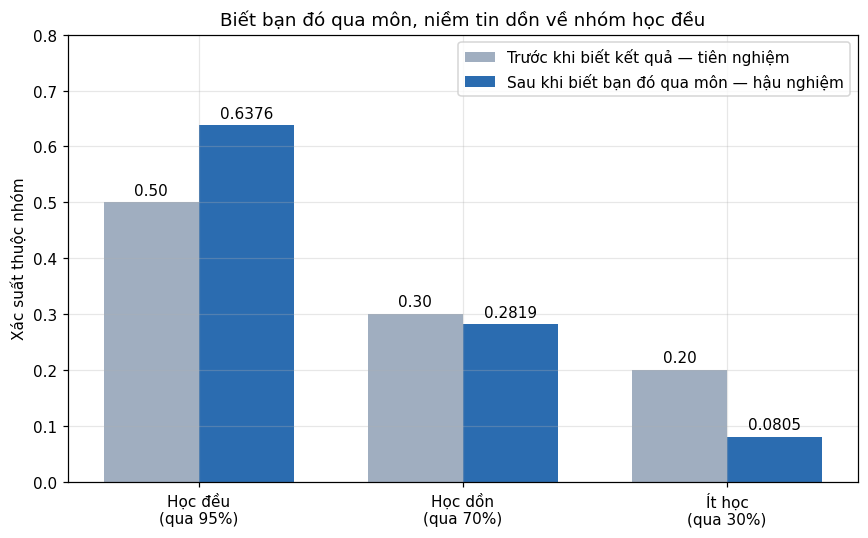

In [17]:
vi_tri = np.arange(3)
do_rong = 0.36
fig, ax = plt.subplots(figsize=(8, 5))
cot_truoc = ax.bar(vi_tri - do_rong / 2, ty_le_nhom, do_rong, color="#a0aec0",
                   label="Trước khi biết kết quả — tiên nghiệm")
cot_sau = ax.bar(vi_tri + do_rong / 2, hau_nghiem, do_rong, color="#2b6cb0",
                 label="Sau khi biết bạn đó qua môn — hậu nghiệm")
ax.bar_label(cot_truoc, fmt="%.2f", padding=3)
ax.bar_label(cot_sau, fmt="%.4f", padding=3)
ax.set_xticks(vi_tri, ["Học đều\n(qua 95%)", "Học dồn\n(qua 70%)", "Ít học\n(qua 30%)"])
ax.set_ylim(0, 0.8)
ax.set_ylabel("Xác suất thuộc nhóm")
ax.set_title("Biết bạn đó qua môn, niềm tin dồn về nhóm học đều")
ax.legend(loc="upper right")
plt.tight_layout()
luu_hinh("bai1_bayes_ba_nhom.png")

**Kết quả:** xác suất qua môn chung là $0.5 \cdot 0.95 + 0.3 \cdot 0.70 + 0.2 \cdot 0.30 = 0.745$. Biết
một bạn đã qua môn thì:

| Nhóm | Tiên nghiệm | Hậu nghiệm |
|---|---:|---:|
| Học đều | 0.50 | **0.6376** |
| Học dồn | 0.30 | **0.2819** |
| Ít học | 0.20 | **0.0805** |

Ba con số cộng lại đúng bằng **1.0000**, và cách đếm trên 1000 sinh viên (475 + 210 + 60 = 745 bạn qua)
cho đúng các tỷ lệ đó. Thông tin "đã qua môn" làm niềm tin vào nhóm học đều **tăng** từ 0.50 lên 0.64,
còn nhóm ít học **giảm** từ 0.20 xuống 0.08 — đúng chiều trực giác. Đáng chú ý là nhóm học dồn gần như
giữ nguyên (0.30 → 0.28): tỷ lệ qua 0.70 của nhóm này chỉ nhỉnh hơn mức chung 0.745 một chút, nên bằng
chứng "qua môn" hầu như không nói thêm gì về nhóm đó.

## Bài tập 2 — Từ nào tố cáo mạnh nhất

Huấn luyện `MultinomialNB` trên **toàn bộ 300 tin nhắn**. Dùng thuộc tính `feature_log_prob_` để tính
hiệu giữa hai lớp cho từng từ, rồi in ra **5 từ tố cáo tin rác mạnh nhất** và **5 từ cho thấy tin
thường mạnh nhất**.

Gợi ý của đề: `feature_log_prob_` là một mảng hai dòng, dòng 0 cho lớp 0 và dòng 1 cho lớp 1. Lấy
`mo_hinh.feature_log_prob_[1] - mo_hinh.feature_log_prob_[0]` rồi sắp xếp.

In [18]:
"""Bai 2: tim 5 tu to cao tin rac manh nhat va 5 tu cho thay tin thuong manh nhat."""

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

tin_nhan = pd.read_csv(DUONG_DAN_TIN)
bo_dem_tu = CountVectorizer(token_pattern=r"(?u)\S+")
bang_dem = bo_dem_tu.fit_transform(tin_nhan["noi_dung"])

bo_loc_toan_bo = MultinomialNB().fit(bang_dem, tin_nhan["la_rac"])   # hoc tren ca 300 tin

# Hieu loga: log P(tu | rac) - log P(tu | thuong)
hieu_loga = bo_loc_toan_bo.feature_log_prob_[1] - bo_loc_toan_bo.feature_log_prob_[0]
danh_sach_tu = bo_dem_tu.get_feature_names_out()
bang_hieu = pd.DataFrame({"tu": danh_sach_tu, "hieu_loga": hieu_loga,
                          "gap_bao_nhieu_lan": np.exp(hieu_loga)})
bang_hieu = bang_hieu.sort_values("hieu_loga", ascending=False).reset_index(drop=True)

print("5 tu to cao tin RAC manh nhat:")
print(bang_hieu.head(5).round(4).to_string(index=False))
print()
print("5 tu cho thay tin THUONG manh nhat:")
print(bang_hieu.tail(5).iloc[::-1].round(4).to_string(index=False))
print()
print("Ba tu gan nhu trung lap (hieu loga gan 0 nhat):")
print(bang_hieu.iloc[(bang_hieu["hieu_loga"].abs()).argsort()[:3]].round(4).to_string(index=False))

5 tu to cao tin RAC manh nhat:
   tu  hieu_loga  gap_bao_nhieu_lan
  mãi     3.2034            24.6169
  tay     2.9056            18.2762
 ngay     2.6618            14.3226
 miễn     2.4795            11.9355
trúng     2.3742            10.7419

5 tu cho thay tin THUONG manh nhat:
   tu  hieu_loga  gap_bao_nhieu_lan
  lớp    -2.6122             0.0734
   em    -2.5618             0.0772
  bài    -2.2946             0.1008
  báo    -2.2741             0.1029
phòng    -2.2741             0.1029

Ba tu gan nhu trung lap (hieu loga gan 0 nhat):
 tu  hieu_loga  gap_bao_nhieu_lan
cho     0.0048             1.0048
 có     0.0499             1.0511
này     0.0538             1.0553


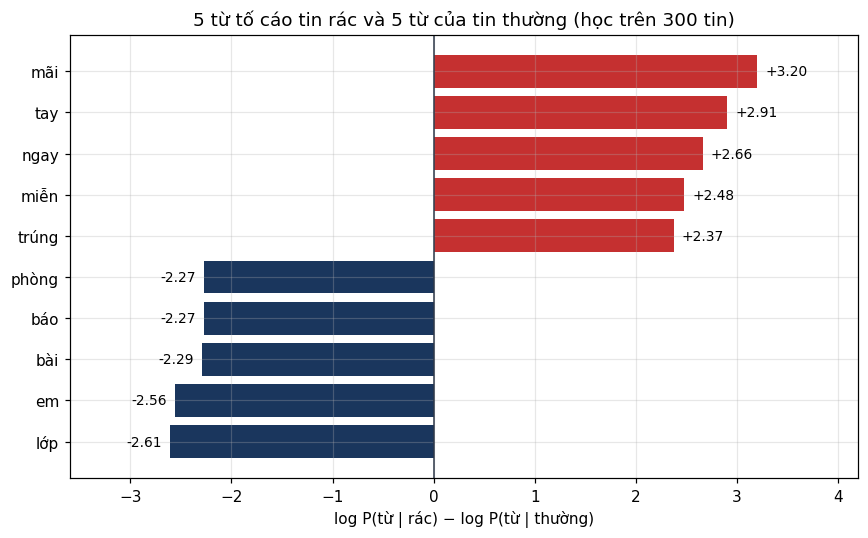

In [19]:
nam_rac = bang_hieu.head(5)
nam_thuong = bang_hieu.tail(5)
# Sap tang dan: tu manh nhat cua tin thuong o duoi cung, cua tin rac o tren cung
hai_nhom = pd.concat([nam_thuong.iloc[::-1], nam_rac.iloc[::-1]])

plt.figure(figsize=(8, 5))
plt.barh(hai_nhom["tu"], hai_nhom["hieu_loga"],
         color=np.where(hai_nhom["hieu_loga"] > 0, MAU_RAC, MAU_THUONG))
for gia_tri, vi_tri_y in zip(hai_nhom["hieu_loga"], range(len(hai_nhom))):
    plt.text(gia_tri + (0.08 if gia_tri > 0 else -0.08), vi_tri_y, f"{gia_tri:+.2f}",
             va="center", ha="left" if gia_tri > 0 else "right", fontsize=9)
plt.axvline(0, color="#2d3748", linewidth=1)
plt.xlim(-3.6, 4.2)
plt.xlabel("log P(từ | rác) − log P(từ | thường)")
plt.title("5 từ tố cáo tin rác và 5 từ của tin thường (học trên 300 tin)")
plt.tight_layout()
luu_hinh("bai2_tu_to_cao_manh_nhat.png")

**Kết quả:** 5 từ tố cáo tin rác mạnh nhất là **mãi, tay, ngay, miễn, trúng**; 5 từ của tin thường mạnh
nhất là **lớp, em, bài, báo, phòng**.

Cách đọc con số: hiệu loga của `mãi` là +3.20, tức $e^{3.20} \approx 24.6$ — **từ `mãi` gặp ở tin rác
nhiều gấp khoảng 25 lần** so với ở tin thường (tính theo tỷ lệ trong tổng số từ của mỗi lớp). Ngược lại
`lớp` có hiệu −2.61, tức gặp ở tin thường nhiều gấp khoảng 13.6 lần. Khi phân loại, mỗi lần một từ xuất
hiện, hiệu loga của nó được **cộng** vào điểm của tin — nên đây đúng là "sức tố cáo" của từng từ. Những từ
có hiệu gần 0 (như `lúc` ở Bước 2) cộng vào gần như không làm lệch bên nào.

So với Hình 1 (mô hình chỉ học trên 225 tin của tập học), danh sách gần như giống nhau nhưng **thứ tự
đổi chút ít**: `trúng` tụt từ hạng 3 xuống hạng 5 bên rác; bên thường `em` nhảy từ hạng 7 lên hạng 2 còn
`gửi` rơi khỏi top 5. Các con số đếm thay đổi một chút khi thêm 75 tin, nên thứ hạng của những từ có hiệu
loga sát nhau cũng đổi theo. Ba từ trung lập nhất là `cho`, `có`, `này` — hiệu loga gần 0, gặp ở hai lớp
nhiều như nhau.

## Bài tập 3 — Đổi tham số làm trơn

Chạy lại bộ lọc với `alpha` lần lượt bằng **0.001, 0.1, 1.0, 10.0 và 100.0**. Với mỗi giá trị, in ra
accuracy, precision và recall trên tập kiểm tra. Nhận xét: **alpha lớn quá thì chuyện gì xảy ra, và
vì sao?**

In [20]:
"""Bai 3: chay lai bo loc voi nhieu gia tri alpha."""

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

tin_nhan = pd.read_csv(DUONG_DAN_TIN)
bo_dem_tu = CountVectorizer(token_pattern=r"(?u)\S+")
bang_dem = bo_dem_tu.fit_transform(tin_nhan["noi_dung"])
nhan = tin_nhan["la_rac"]

X_train, X_test, y_train, y_test = train_test_split(
    bang_dem, nhan, test_size=0.25, random_state=17, stratify=nhan
)


def cham_diem_alpha(alpha):
    """Huan luyen bo loc voi alpha cho truoc, tra ve cac so do tren tap kiem tra."""
    bo_loc = MultinomialNB(alpha=alpha).fit(X_train, y_train)
    nhan_du_doan = bo_loc.predict(X_test)
    xac_suat_rac = bo_loc.predict_proba(X_test)[:, 1]
    return {
        "alpha": alpha,
        "accuracy": accuracy_score(y_test, nhan_du_doan),
        "precision": precision_score(y_test, nhan_du_doan, zero_division=0),
        "recall": recall_score(y_test, nhan_du_doan),
        "p_rac_nho_nhat": xac_suat_rac.min(),
        "p_rac_lon_nhat": xac_suat_rac.max(),
        "so_tin_doan_rac": int(nhan_du_doan.sum()),
    }


print("Nam gia tri alpha theo de bai:")
bang_de_bai = pd.DataFrame([cham_diem_alpha(a) for a in [0.001, 0.1, 1.0, 10.0, 100.0]])
print(bang_de_bai.round(4).to_string(index=False))
print()

print("Lam them: day alpha len cao hon nua de xem luc nao bo loc hong:")
bang_mo_rong = pd.DataFrame([cham_diem_alpha(a) for a in [300.0, 1000.0, 10000.0]])
print(bang_mo_rong.round(4).to_string(index=False))
print()
print(f"Ty le tin thuong trong tap kiem tra: {1 - y_test.mean():.4f}")

Nam gia tri alpha theo de bai:
  alpha  accuracy  precision  recall  p_rac_nho_nhat  p_rac_lon_nhat  so_tin_doan_rac
  0.001    0.9467        1.0  0.8667          0.0000          1.0000               26
  0.100    0.9467        1.0  0.8667          0.0000          1.0000               26
  1.000    0.9467        1.0  0.8667          0.0000          1.0000               26
 10.000    0.9467        1.0  0.8667          0.0001          1.0000               26
100.000    0.9467        1.0  0.8667          0.0654          0.8842               26

Lam them: day alpha len cao hon nua de xem luc nao bo loc hong:
  alpha  accuracy  precision  recall  p_rac_nho_nhat  p_rac_lon_nhat  so_tin_doan_rac
  300.0      0.92        1.0     0.8          0.2187          0.6215               24
 1000.0      0.60        0.0     0.0          0.3359          0.4690                0
10000.0      0.60        0.0     0.0          0.3932          0.4069                0

Ty le tin thuong trong tap kiem tra: 0.6000

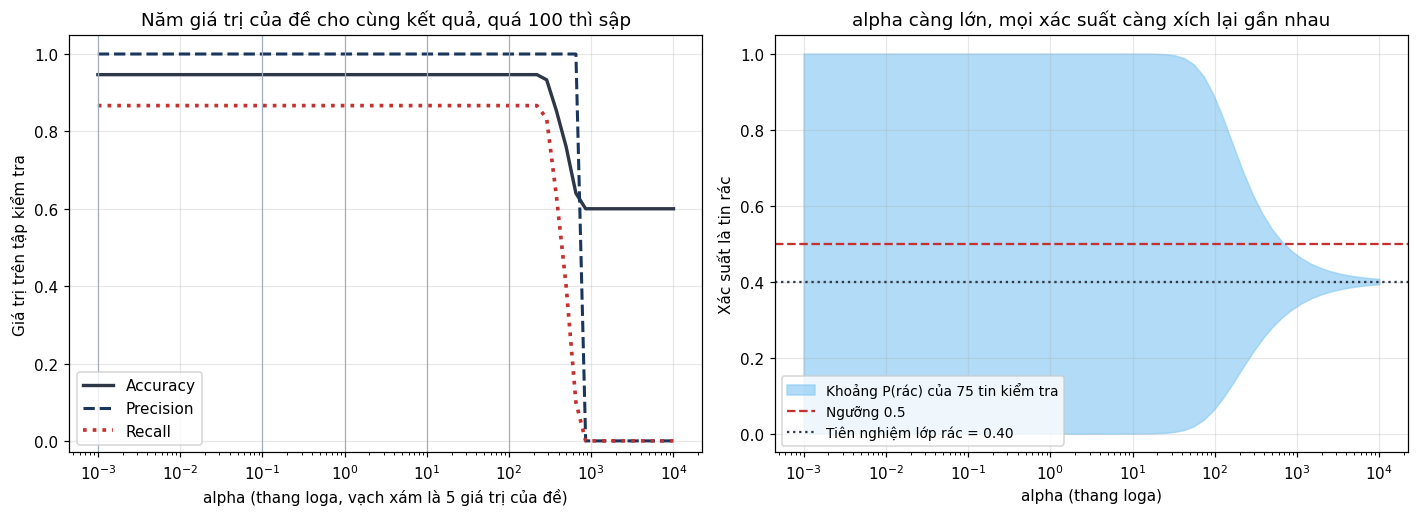

In [21]:
luoi_alpha_bai3 = np.logspace(-3, 4, 60)
bang_luoi = pd.DataFrame([cham_diem_alpha(a) for a in luoi_alpha_bai3])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.plot(bang_luoi["alpha"], bang_luoi["accuracy"], color="#2d3748", linewidth=2.2, label="Accuracy")
ax1.plot(bang_luoi["alpha"], bang_luoi["precision"], "--", color=MAU_THUONG, linewidth=2, label="Precision")
ax1.plot(bang_luoi["alpha"], bang_luoi["recall"], ":", color=MAU_RAC, linewidth=2.4, label="Recall")
for a in [0.001, 0.1, 1.0, 10.0, 100.0]:
    ax1.axvline(a, color="#a0aec0", linewidth=0.8)
ax1.set_xscale("log")
ax1.set_ylim(-0.03, 1.05)
ax1.set_xlabel("alpha (thang loga, vạch xám là 5 giá trị của đề)")
ax1.set_ylabel("Giá trị trên tập kiểm tra")
ax1.set_title("Năm giá trị của đề cho cùng kết quả, quá 100 thì sập")
ax1.legend(loc="lower left")

ax2.fill_between(bang_luoi["alpha"], bang_luoi["p_rac_nho_nhat"], bang_luoi["p_rac_lon_nhat"],
                 color="#90cdf4", alpha=0.7, label="Khoảng P(rác) của 75 tin kiểm tra")
ax2.axhline(0.5, linestyle="--", color=MAU_RAC, label="Ngưỡng 0.5")
ax2.axhline(y_train.mean(), linestyle=":", color="#2d3748",
            label=f"Tiên nghiệm lớp rác = {y_train.mean():.2f}")
ax2.set_xscale("log")
ax2.set_xlabel("alpha (thang loga)")
ax2.set_ylabel("Xác suất là tin rác")
ax2.set_title("alpha càng lớn, mọi xác suất càng xích lại gần nhau")
ax2.legend(loc="lower left", fontsize=9)
plt.tight_layout()
luu_hinh("bai3_tham_so_lam_tron.png")

**Kết quả:** với cả năm giá trị đề cho, accuracy, precision, recall **giống hệt nhau** — 0.9467, 1.0000,
0.8667. Nhìn thoáng qua thì tưởng alpha không quan trọng, nhưng cột xác suất kể một câu chuyện khác:

- Từ 0.001 tới 10, xác suất rác của các tin kiểm tra vẫn trải từ gần 0 tới gần 1 — mô hình rất dứt khoát.
- Ở **alpha = 100**, khoảng đó co lại chỉ còn **0.07 → 0.88**: mô hình bắt đầu "lưỡng lự" với mọi tin, dù
  nhãn chưa đổi.
- Đẩy tiếp lên **alpha = 300** thì recall tụt xuống 0.80; tới **alpha = 1000** thì mọi xác suất nằm
  trong khoảng **0.34 → 0.47**, không tin nào vượt ngưỡng 0.5, bộ lọc **không chặn được tin rác nào**
  (recall = 0) và accuracy rơi về **0.6000 — đúng bằng tỷ lệ tin thường**, tức mô hình lười "đoán thường
  hết" của bài 2.

**Vì sao:** công thức làm trơn là $(\text{đếm}_{jk} + \alpha) / (\text{tổng}_k + \alpha V)$. Khi $\alpha$
lớn hơn hẳn các số đếm thật (mỗi lớp chỉ có vài trăm từ), phần $\alpha$ lấn át dữ liệu và **mọi xác suất
từ đều tiến về $1/V = 1/40$ ở cả hai lớp** — từ `mãi` hay từ `lớp` đều "nặng" như nhau. Khi đó hiệu loga
của mọi từ tiến về 0, bằng chứng từ tin nhắn không còn đẩy được về bên nào, và chỉ còn **tiên nghiệm**
quyết định. Vì lớp thường chiếm 60%, tiên nghiệm kéo mọi tin về lớp thường. Nói gọn: **alpha lớn quá thì
mô hình "làm trơn" mất luôn thông tin**, ngược với alpha = 0 làm mô hình tê liệt vì số 0. Alpha nhỏ cỡ
0.1 – 1 là vùng an toàn.

## Bài tập 4 — Tự viết bộ lọc không dùng thư viện

Dựa vào `d4_lam_tron.py`, viết một bộ lọc hoàn chỉnh cho toàn bộ 300 tin nhắn: **tự đếm từ, tự làm
trơn, tự tính điểm cho hai lớp bằng tổng loga** thay vì tích. Chia dữ liệu bằng `train_test_split` với
`random_state=17` rồi so accuracy của bộ lọc tự viết với `MultinomialNB`. Hai con số phải rất gần nhau;
nếu lệch nhiều thì có lỗi ở đâu đó.

So với kho tí hon ở Bước 4, bộ lọc thật cần thêm ba thứ:

1. **Tiên nghiệm thật** — hai lớp không còn cân bằng (60% thường, 40% rác) nên không thể cứ đặt 0.5.
2. **Tổng loga** — tin dài nhân nhiều xác suất nhỏ sẽ tràn dưới.
3. **Chỉ học trên tập học** — từ điển, số đếm, tiên nghiệm đều lấy từ 225 tin; 75 tin kiểm tra chỉ dùng để chấm.

In [22]:
"""Bai 4: tu viet bo loc Naive Bayes da thuc, cong loga thay vi nhan."""

import math
from collections import Counter

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

ALPHA = 1.0

tin_nhan = pd.read_csv(DUONG_DAN_TIN)
# Chia tren chinh bang van ban; cung random_state va stratify nen trung voi cach chia o Buoc 3
tin_hoc, tin_kiem_tra = train_test_split(
    tin_nhan, test_size=0.25, random_state=17, stratify=tin_nhan["la_rac"]
)


def tach_tu(cau):
    """Tach tu bang khoang trang, viet thuong nhu CountVectorizer mac dinh."""
    return cau.lower().split()


# ---- 1. Hoc: chi la dem, tren dung tap hoc ----
so_tin_moi_lop = Counter(tin_hoc["la_rac"])
dem_tu_moi_lop = {0: Counter(), 1: Counter()}
for cau, lop in zip(tin_hoc["noi_dung"], tin_hoc["la_rac"]):
    dem_tu_moi_lop[lop].update(tach_tu(cau))

tu_dien = sorted(set(dem_tu_moi_lop[0]) | set(dem_tu_moi_lop[1]))
so_tu_tu_dien = len(tu_dien)
tong_so_tu_moi_lop = {lop: sum(dem_tu_moi_lop[lop].values()) for lop in (0, 1)}

# Tien nghiem = ty le tung lop trong tap hoc, luu san duoi dang loga
log_tien_nghiem = {lop: math.log(so_tin_moi_lop[lop] / len(tin_hoc)) for lop in (0, 1)}

# Xac suat tu co lam tron Laplace, luu san duoi dang loga
log_xac_suat_tu = {
    lop: {tu: math.log((dem_tu_moi_lop[lop][tu] + ALPHA)
                       / (tong_so_tu_moi_lop[lop] + ALPHA * so_tu_tu_dien))
          for tu in tu_dien}
    for lop in (0, 1)
}


# ---- 2. Du doan: cong loga ----
def diem_loga(cau, lop):
    """log P(lop) + tong log P(tu | lop). Tu ngoai tu dien bi bo qua, giong CountVectorizer."""
    diem = log_tien_nghiem[lop]
    for tu in tach_tu(cau):
        if tu in log_xac_suat_tu[lop]:
            diem += log_xac_suat_tu[lop][tu]
    return diem


def loc_tin(cau):
    """1 neu la tin rac, 0 neu la tin thuong. Hoa diem thi chon lop 0 nhu scikit-learn."""
    return 1 if diem_loga(cau, 1) > diem_loga(cau, 0) else 0


du_doan_tu_viet = np.array([loc_tin(cau) for cau in tin_kiem_tra["noi_dung"]])
nhan_that = tin_kiem_tra["la_rac"].to_numpy()

# ---- 3. Doi chung voi MultinomialNB tren cung tap hoc ----
bo_dem_tu = CountVectorizer(token_pattern=r"(?u)\S+")
X_hoc = bo_dem_tu.fit_transform(tin_hoc["noi_dung"])
X_kiem_tra = bo_dem_tu.transform(tin_kiem_tra["noi_dung"])
bo_loc_thu_vien = MultinomialNB(alpha=ALPHA).fit(X_hoc, tin_hoc["la_rac"])
du_doan_thu_vien = bo_loc_thu_vien.predict(X_kiem_tra)

print(f"So tin hoc / kiem tra       : {len(tin_hoc)} / {len(tin_kiem_tra)}")
print(f"So tu trong tu dien tu viet : {so_tu_tu_dien}   (thu vien: {len(bo_dem_tu.vocabulary_)})")
print(f"Tien nghiem tu viet         : thuong {math.exp(log_tien_nghiem[0]):.4f}, "
      f"rac {math.exp(log_tien_nghiem[1]):.4f}")
print()
print(f"Accuracy bo loc tu viet : {accuracy_score(nhan_that, du_doan_tu_viet):.4f}")
print(f"Accuracy MultinomialNB  : {accuracy_score(nhan_that, du_doan_thu_vien):.4f}")
print(f"So tin hai ben doan khac nhau: {(du_doan_tu_viet != du_doan_thu_vien).sum()}")
print()
print("Ma tran nham lan tu viet (TN, FP, FN, TP):", confusion_matrix(nhan_that, du_doan_tu_viet).ravel())
print()

# Soi sau hon: so sanh truc tiep diem loga, khong chi so sanh nhan
hieu_tu_viet = np.array([diem_loga(cau, 1) - diem_loga(cau, 0) for cau in tin_kiem_tra["noi_dung"]])
log_hau_nghiem = bo_loc_thu_vien.predict_joint_log_proba(X_kiem_tra)
hieu_thu_vien = log_hau_nghiem[:, 1] - log_hau_nghiem[:, 0]
print(f"Chenh lech lon nhat giua diem loga tu viet va thu vien: "
      f"{np.abs(hieu_tu_viet - hieu_thu_vien).max():.2e}")

# Va thu lai cam bay tran duoi: neu nhan truc tiep thay vi cong loga
cau_dai_nhat = max(tin_kiem_tra["noi_dung"], key=lambda c: len(c.split()))
tich_truc_tiep = math.exp(log_tien_nghiem[1])
for tu in tach_tu(cau_dai_nhat * 40):          # gia lap mot tin dai 40 lan
    if tu in log_xac_suat_tu[1]:
        tich_truc_tiep *= math.exp(log_xac_suat_tu[1][tu])
print(f"Tin dai gap 40 lan, nhan truc tiep cho lop rac: {tich_truc_tiep}  (tran duoi)")
print(f"Cung tin do, cong loga cho lop rac           : {diem_loga(cau_dai_nhat * 40, 1):.2f}")

So tin hoc / kiem tra       : 225 / 75
So tu trong tu dien tu viet : 40   (thu vien: 40)
Tien nghiem tu viet         : thuong 0.6000, rac 0.4000

Accuracy bo loc tu viet : 0.9467
Accuracy MultinomialNB  : 0.9467
So tin hai ben doan khac nhau: 0

Ma tran nham lan tu viet (TN, FP, FN, TP): [45  0  4 26]

Chenh lech lon nhat giua diem loga tu viet va thu vien: 1.42e-14
Tin dai gap 40 lan, nhan truc tiep cho lop rac: 0.0  (tran duoi)
Cung tin do, cong loga cho lop rac           : -1517.18


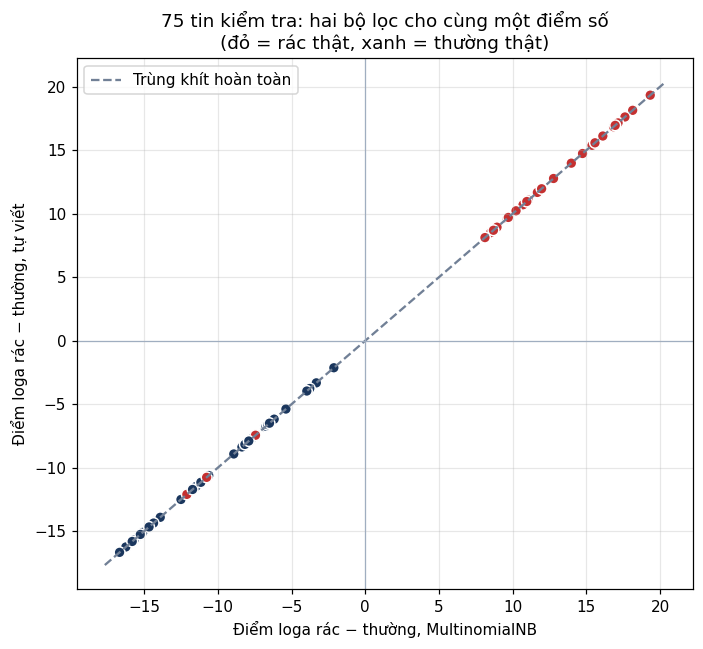

In [23]:
plt.figure(figsize=(6.5, 6))
plt.scatter(hieu_thu_vien, hieu_tu_viet, s=50, edgecolor="white",
            c=np.where(nhan_that == 1, MAU_RAC, MAU_THUONG))
canh = [min(hieu_thu_vien.min(), hieu_tu_viet.min()) - 1, max(hieu_thu_vien.max(), hieu_tu_viet.max()) + 1]
plt.plot(canh, canh, "--", color="#718096", label="Trùng khít hoàn toàn")
plt.axhline(0, color="#a0aec0", linewidth=0.8)
plt.axvline(0, color="#a0aec0", linewidth=0.8)
plt.xlabel("Điểm loga rác − thường, MultinomialNB")
plt.ylabel("Điểm loga rác − thường, tự viết")
plt.title("75 tin kiểm tra: hai bộ lọc cho cùng một điểm số\n(đỏ = rác thật, xanh = thường thật)")
plt.legend(loc="upper left")
plt.tight_layout()
luu_hinh("bai4_tu_viet_so_voi_thu_vien.png")

**Kết quả:** bộ lọc tự viết đạt accuracy **0.9467**, trùng đúng với `MultinomialNB`, **không có tin nào
hai bên đoán khác nhau**, và ma trận nhầm lẫn cũng y hệt Bước 3 (TN = 45, FP = 0, FN = 4, TP = 26). Không
chỉ nhãn trùng: hiệu điểm loga của từng tin cũng trùng tới cỡ $10^{-14}$ — chỉ là sai số làm tròn của máy
tính. Mọi điểm trong hình nằm thẳng trên đường chéo.

**Giải thích cơ chế — vì sao tự viết khớp được tới vậy:** `MultinomialNB` không làm gì bí ẩn, nó làm đúng
bốn việc mà mã tự viết làm:

1. **Đếm** số lần mỗi từ xuất hiện trong từng lớp của tập học, và số tin của từng lớp. Đây là *toàn bộ*
   quá trình huấn luyện — không có vòng lặp dò tìm như gradient descent ở bài 1.
2. **Tiên nghiệm** $\mathbb{P}(\text{lớp})$ = tỷ lệ số tin của lớp đó trong tập học: 135/225 = 0.6 cho
   thường, 90/225 = 0.4 cho rác. Nếu cứ đặt 0.5 như kho tí hon ở Bước 4 thì điểm sẽ lệch một hằng số
   $\log(0.6/0.4)$ và vài tin sát biên có thể đổi nhãn — đó là lỗi đầu tiên cần nghi nếu hai bên lệch.
3. **Làm trơn Laplace**: $(\text{đếm} + \alpha) / (\text{tổng số từ của lớp} + \alpha V)$, với $V$ là số
   từ trong từ điển (40). Quên $\alpha V$ ở mẫu số thì các xác suất không còn cộng lại bằng 1 và điểm hai
   lớp bị lệch theo kiểu khác nhau.
4. **Cộng loga** thay vì nhân: điểm = $\log \mathbb{P}(\text{lớp}) + \sum \log \mathbb{P}(\text{từ} \mid \text{lớp})$,
   mỗi lần một từ xuất hiện là cộng thêm một lần (từ lặp hai lần thì cộng hai lần, đúng tinh thần "đếm"
   của túi từ). Vì loga đồng biến nên lớp có tổng loga lớn hơn cũng là lớp có tích lớn hơn — kết luận
   không đổi, nhưng không còn tràn dưới. Dòng cuối của kết quả cho thấy điều đó: với một tin dài gấp 40
   lần, phép nhân trực tiếp rơi về **0.0** còn tổng loga vẫn là một con số dùng được.

Hai chi tiết nhỏ nhưng phải khớp với thư viện thì mới ra trùng tuyệt đối: **viết thường** trước khi tách
từ (`CountVectorizer` mặc định `lowercase=True`) và **bỏ qua từ ngoài từ điển** (thư viện cũng không có cột
cho từ đó). Cuối cùng, từ điển phải lập **chỉ từ tập học**; nếu lập từ cả 300 tin thì $V$ có thể lớn hơn
và mọi xác suất đổi theo — một dạng rò rỉ dữ liệu kiểm tra vào lúc học.

## Bài tập 5 — Chọn sai biến thể Naive Bayes

Chạy `MultinomialNB` trên bộ dữ liệu sinh viên với hai cột `gio_on` và `diem_giua_ky`. In ra accuracy rồi
so với `GaussianNB` ở Bước 5. Chương trình có báo lỗi không? Con số accuracy ra bao nhiêu? Giải thích vì
sao dùng `MultinomialNB` ở đây là **sai về nguyên tắc**, dù nó vẫn chạy.

In [24]:
"""Bai 5: dung nham MultinomialNB cho so lieu lien tuc."""

from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB

sinh_vien = pd.read_csv(DUONG_DAN_SV)
X_sv = sinh_vien[["gio_on", "diem_giua_ky"]]
y_sv = sinh_vien["qua_mon"]

X_train, X_test, y_train, y_test = train_test_split(
    X_sv, y_sv, test_size=0.25, random_state=17, stratify=y_sv
)

mo_hinh_sai = MultinomialNB().fit(X_train, y_train)      # khong bao loi gi ca
mo_hinh_dung = GaussianNB().fit(X_train, y_train)

acc_sai = accuracy_score(y_test, mo_hinh_sai.predict(X_test))
acc_dung = accuracy_score(y_test, mo_hinh_dung.predict(X_test))
print(f"MultinomialNB (chon sai) : accuracy = {acc_sai:.4f}")
print(f"GaussianNB    (chon dung): accuracy = {acc_dung:.4f}")
print()

# MultinomialNB coi moi dong la mot "tin nhan" va gio_on, diem_giua_ky la so lan hai "tu" xuat hien.
# Xem no hoc duoc gi:
ty_le_tu = np.exp(mo_hinh_sai.feature_log_prob_)
print("MultinomialNB hoc duoc 'ty le tu' trong moi lop:")
print(f"  {'':10s} {'gio_on':>8s} {'diem_giua_ky':>13s}")
for lop, ten_lop in enumerate(["Lop rot", "Lop qua"]):
    print(f"  {ten_lop:10s} {ty_le_tu[lop, 0]:8.4f} {ty_le_tu[lop, 1]:13.4f}")
hieu_loga_sv = mo_hinh_sai.feature_log_prob_[1] - mo_hinh_sai.feature_log_prob_[0]
print(f"Moi gio on them vao diem 'qua'    : {hieu_loga_sv[0]:+.4f}")
print(f"Moi diem giua ky them vao diem 'qua': {hieu_loga_sv[1]:+.4f}  <- AM: diem cao bi coi la dau hieu rot!")
print()

# Hai ban cung 15 gio on, chi khac diem giua ky
hai_ban = pd.DataFrame({"gio_on": [15.0, 15.0], "diem_giua_ky": [3.0, 9.0]})
print("Hai ban cung on 15 gio:")
for (_, ban), p_sai, p_dung in zip(hai_ban.iterrows(),
                                   mo_hinh_sai.predict_proba(hai_ban)[:, 1],
                                   mo_hinh_dung.predict_proba(hai_ban)[:, 1]):
    print(f"  diem giua ky {ban.diem_giua_ky:.0f}: P(qua) Multinomial = {p_sai:.4f}, Gaussian = {p_dung:.4f}")
print()

# Va mot du lieu co so am thi MultinomialNB moi chiu bao loi
try:
    MultinomialNB().fit(X_train - X_train.mean(), y_train)
except ValueError as loi:
    print("Khi dua so am vao (vi du sau khi tru trung binh):", loi)

MultinomialNB (chon sai) : accuracy = 0.8000
GaussianNB    (chon dung): accuracy = 0.9000

MultinomialNB hoc duoc 'ty le tu' trong moi lop:
               gio_on  diem_giua_ky
  Lop rot      0.6715        0.3285
  Lop qua      0.7491        0.2509
Moi gio on them vao diem 'qua'    : +0.1094
Moi diem giua ky them vao diem 'qua': -0.2695  <- AM: diem cao bi coi la dau hieu rot!

Hai ban cung on 15 gio:
  diem giua ky 3: P(qua) Multinomial = 0.7670, Gaussian = 0.1247
  diem giua ky 9: P(qua) Multinomial = 0.3952, Gaussian = 0.9608

Khi dua so am vao (vi du sau khi tru trung binh): Negative values in data passed to MultinomialNB (input X).


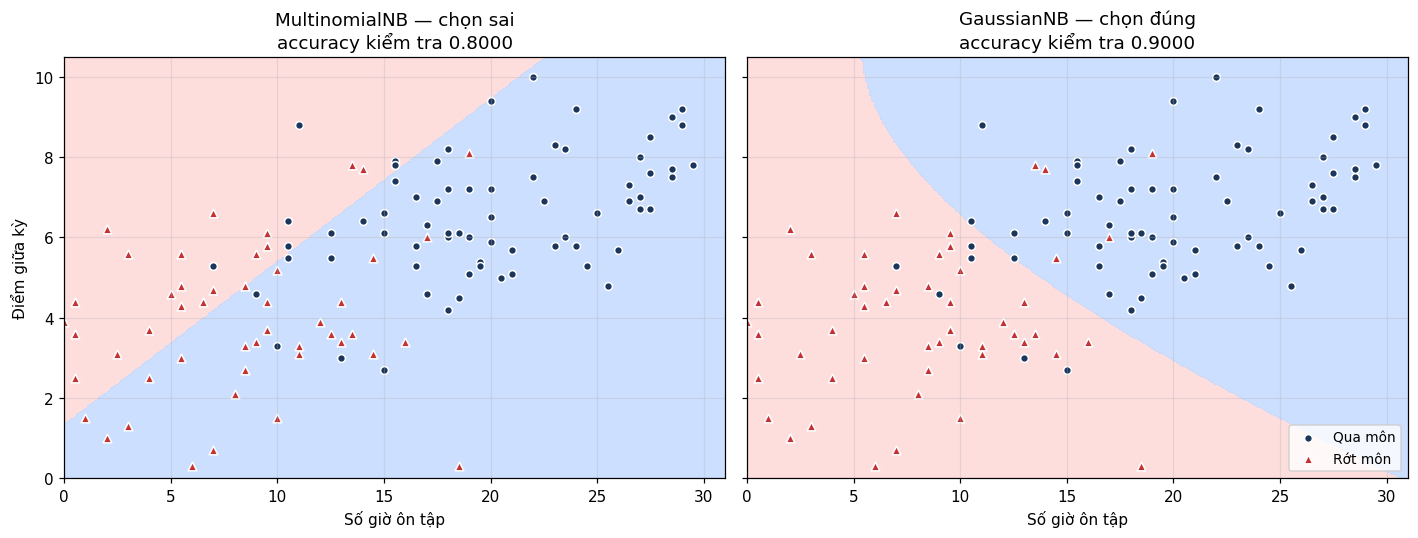

In [25]:
luoi_x1, luoi_x2 = np.meshgrid(np.linspace(0, 31, 300), np.linspace(0, 10.5, 300))
luoi_sv = pd.DataFrame({"gio_on": luoi_x1.ravel(), "diem_giua_ky": luoi_x2.ravel()})
nhom_qua_sv = sinh_vien[sinh_vien["qua_mon"] == 1]
nhom_rot_sv = sinh_vien[sinh_vien["qua_mon"] == 0]

fig, cac_truc = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (ten, mh, acc) in zip(cac_truc, [("MultinomialNB — chọn sai", mo_hinh_sai, acc_sai),
                                         ("GaussianNB — chọn đúng", mo_hinh_dung, acc_dung)]):
    vung = mh.predict(luoi_sv).reshape(luoi_x1.shape)
    ax.contourf(luoi_x1, luoi_x2, vung, levels=[-0.5, 0.5, 1.5],
                colors=["#fed7d7", "#c3dafe"], alpha=0.85)
    ax.scatter(nhom_qua_sv["gio_on"], nhom_qua_sv["diem_giua_ky"], s=26, marker="o",
               color=MAU_THUONG, edgecolor="white", label="Qua môn")
    ax.scatter(nhom_rot_sv["gio_on"], nhom_rot_sv["diem_giua_ky"], s=32, marker="^",
               color=MAU_RAC, edgecolor="white", label="Rớt môn")
    ax.set_title(f"{ten}\naccuracy kiểm tra {acc:.4f}")
    ax.set_xlabel("Số giờ ôn tập")
    ax.set_xlim(0, 31)
    ax.set_ylim(0, 10.5)
cac_truc[0].set_ylabel("Điểm giữa kỳ")
cac_truc[1].legend(loc="lower right", fontsize=9)
plt.tight_layout()
luu_hinh("bai5_chon_sai_bien_the.png")

**Kết quả:** chương trình **không báo lỗi gì cả**. `MultinomialNB` cho accuracy **0.8000**, thấp hơn
`GaussianNB` (**0.9000**) đúng 3 bạn trên 30. Con số 0.80 nghe vẫn "tạm được" — chính vì vậy đây là lỗi
im lặng nguy hiểm: không có dấu hiệu gì cho thấy mô hình đang hiểu sai dữ liệu.

**Vì sao sai về nguyên tắc:** `MultinomialNB` được thiết kế cho **dữ liệu đếm**. Nó coi mỗi sinh viên là
một "tin nhắn", còn `gio_on = 15.5` và `diem_giua_ky = 6.2` là "từ *gio_on* xuất hiện 15.5 lần, từ
*diem_giua_ky* xuất hiện 6.2 lần". Hệ quả:

1. **Nó chỉ nhìn tỷ lệ giữa hai cột, không nhìn giá trị.** Mô hình học "trong lớp qua, cứ 100 *từ* thì
   khoảng 75 là *giờ ôn*, 25 là *điểm*; trong lớp rớt là 67 / 33". Một bạn ôn 4 giờ điểm 1 và một bạn ôn
   20 giờ điểm 5 có cùng tỷ lệ 4 : 1 nên bị đối xử gần như nhau. Hình bên trái cho thấy điều đó: biên quyết
   định là **một đường thẳng xuất phát gần gốc toạ độ** — mọi điểm trên cùng một tia từ gốc nhận cùng một nhãn.
2. **Nó học ngược chiều với điểm giữa kỳ.** Vì lớp qua có tỷ lệ *điểm / giờ ôn* nhỏ hơn (họ ôn rất nhiều
   giờ), hiệu loga của `diem_giua_ky` ra **âm**: mô hình coi điểm giữa kỳ cao là dấu hiệu rớt. Hai bạn cùng
   ôn 15 giờ, bạn được 9 điểm lại bị cho xác suất qua **thấp hơn** bạn được 3 điểm — vô lý, trong khi
   `GaussianNB` cho kết quả đúng chiều.
3. **Chuyện "số lần xuất hiện" ở đây vô nghĩa.** 15.5 *lần* là gì? Và nếu dữ liệu có số âm (ví dụ sau khi
   chuẩn hoá bằng cách trừ trung bình), `MultinomialNB` mới chịu báo lỗi `Negative values in data` — dòng
   cuối của kết quả. Dữ liệu sinh viên toàn số dương nên lỗi bị che mất.

`GaussianNB` đúng vì nó mô tả mỗi cột của mỗi lớp bằng một đường chuông (trung bình, độ lệch chuẩn) —
đúng bản chất của số liệu liên tục. Bài học: **chọn biến thể theo kiểu dữ liệu**, không theo việc chương
trình có chạy hay không.

## Bài tập 6 — Lớp hiếm và xác suất tiên nghiệm

Từ bộ tin nhắn, tạo một bộ mới **mất cân bằng nặng**: giữ toàn bộ 180 tin thường nhưng chỉ lấy **20 tin
rác đầu tiên**. Huấn luyện lại và chấm điểm. In ra accuracy và recall của lớp rác. Nhận xét: accuracy có
còn phản ánh đúng chất lượng bộ lọc không?

Gợi ý của đề: dùng `recall_score` với `pos_label=1`, và nhớ lại cái bẫy accuracy ở bài 2.

In [26]:
"""Bai 6: bo du lieu mat can bang nang, xem accuracy co con dang tin."""

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

tin_nhan = pd.read_csv(DUONG_DAN_TIN)
tin_thuong = tin_nhan[tin_nhan["la_rac"] == 0]
hai_muoi_tin_rac_dau = tin_nhan[tin_nhan["la_rac"] == 1].head(20)
bo_mat_can_bang = pd.concat([tin_thuong, hai_muoi_tin_rac_dau]).reset_index(drop=True)

print("Bo du lieu moi:", bo_mat_can_bang.shape)
print(bo_mat_can_bang["la_rac"].value_counts().to_string())
print()


def huan_luyen_va_cham(bang_tin, random_state=17):
    """Chia 75/25 co stratify, huan luyen MultinomialNB, tra ve cac so do cua lop rac."""
    bo_dem = CountVectorizer(token_pattern=r"(?u)\S+")
    X_tin = bo_dem.fit_transform(bang_tin["noi_dung"])
    y_nhan = bang_tin["la_rac"]
    X_hoc, X_kt, y_hoc, y_kt = train_test_split(
        X_tin, y_nhan, test_size=0.25, random_state=random_state, stratify=y_nhan
    )
    bo_loc = MultinomialNB().fit(X_hoc, y_hoc)
    du_doan = bo_loc.predict(X_kt)
    return {
        "so_tin_kt": len(y_kt),
        "so_rac_kt": int(y_kt.sum()),
        "accuracy": accuracy_score(y_kt, du_doan),
        "precision_rac": precision_score(y_kt, du_doan, pos_label=1, zero_division=0),
        "recall_rac": recall_score(y_kt, du_doan, pos_label=1),
        "doan_thuong_het": 1 - y_kt.mean(),             # accuracy cua mo hinh luoi
        "tien_nghiem_rac": float(np.exp(bo_loc.class_log_prior_[1])),
        "ma_tran": confusion_matrix(y_kt, du_doan).ravel(),
    }


ket_qua_can_bang = huan_luyen_va_cham(tin_nhan)
ket_qua_lech = huan_luyen_va_cham(bo_mat_can_bang)

print(f"{'':28s} {'Bo goc 180/120':>15s} {'Bo lech 180/20':>15s}")
for khoa, nhan_in in [("so_tin_kt", "So tin kiem tra"), ("so_rac_kt", "  trong do tin rac"),
                      ("tien_nghiem_rac", "Tien nghiem lop rac"),
                      ("accuracy", "Accuracy"), ("precision_rac", "Precision lop rac"),
                      ("recall_rac", "Recall lop rac"),
                      ("doan_thuong_het", "Accuracy neu doan thuong het")]:
    a, b = ket_qua_can_bang[khoa], ket_qua_lech[khoa]
    dinh_dang = "{:15d}" if isinstance(a, int) else "{:15.4f}"
    print(f"{nhan_in:28s} {dinh_dang.format(a)} {dinh_dang.format(b)}")
print(f"{'Ma tran (TN, FP, FN, TP)':28s} {str(ket_qua_can_bang['ma_tran']):>15s} {str(ket_qua_lech['ma_tran']):>15s}")

Bo du lieu moi: (200, 2)
la_rac
0    180
1     20

                              Bo goc 180/120  Bo lech 180/20
So tin kiem tra                           75              50
  trong do tin rac                        30               5
Tien nghiem lop rac                   0.4000          0.1000
Accuracy                              0.9467          0.9800
Precision lop rac                     1.0000          1.0000
Recall lop rac                        0.8667          0.8000
Accuracy neu doan thuong het          0.6000          0.9000
Ma tran (TN, FP, FN, TP)       [45  0  4 26]   [45  0  1  4]


Bo goc 180/120: accuracy TB = 0.9204  |  recall rac TB = 0.8533, thap nhat = 0.7333, cao nhat = 0.9333
Bo lech 180/20: accuracy TB = 0.9727  |  recall rac TB = 0.8067, thap nhat = 0.6000, cao nhat = 1.0000


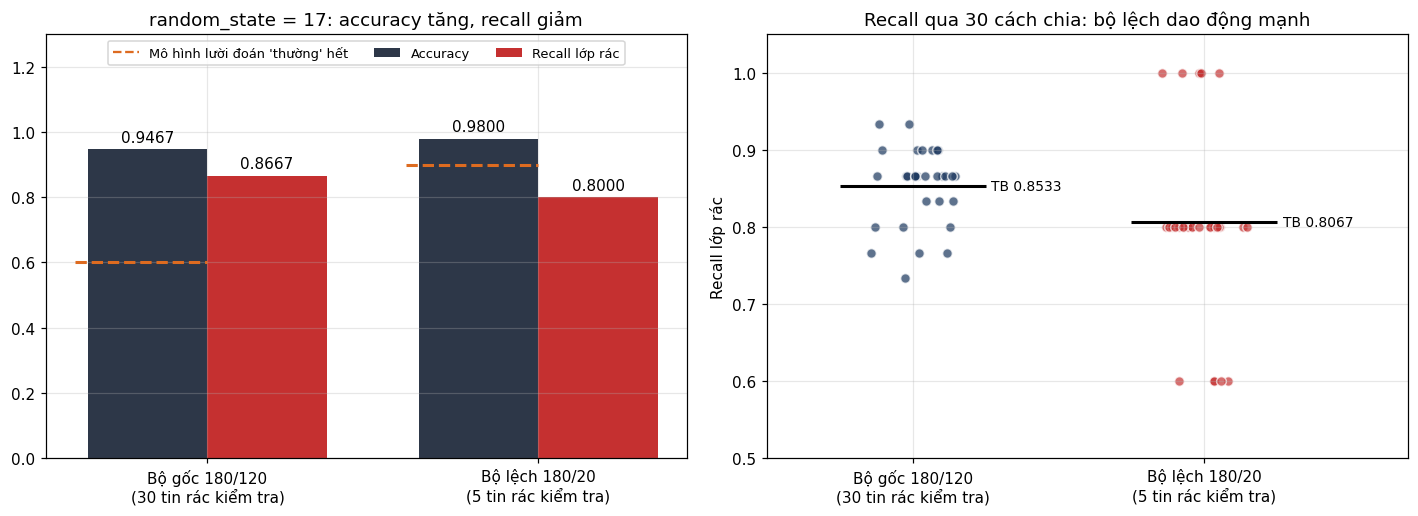

In [27]:
# Lam them: 5 tin rac trong tap kiem tra la qua it de tin mot con so recall.
# Lap lai voi 30 cach chia khac nhau de xem recall dao dong the nao.
nhieu_lan_goc = [huan_luyen_va_cham(tin_nhan, rs) for rs in range(30)]
nhieu_lan_lech = [huan_luyen_va_cham(bo_mat_can_bang, rs) for rs in range(30)]

for ten, ds in [("Bo goc 180/120", nhieu_lan_goc), ("Bo lech 180/20", nhieu_lan_lech)]:
    acc = np.array([k["accuracy"] for k in ds])
    rec = np.array([k["recall_rac"] for k in ds])
    print(f"{ten}: accuracy TB = {acc.mean():.4f}  |  recall rac TB = {rec.mean():.4f}, "
          f"thap nhat = {rec.min():.4f}, cao nhat = {rec.max():.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
vi_tri = np.arange(2)
do_rong = 0.36
cot_acc = ax1.bar(vi_tri - do_rong / 2, [ket_qua_can_bang["accuracy"], ket_qua_lech["accuracy"]],
                  do_rong, color="#2d3748", label="Accuracy")
cot_rec = ax1.bar(vi_tri + do_rong / 2, [ket_qua_can_bang["recall_rac"], ket_qua_lech["recall_rac"]],
                  do_rong, color=MAU_RAC, label="Recall lớp rác")
ax1.bar_label(cot_acc, fmt="%.4f", padding=3)
ax1.bar_label(cot_rec, fmt="%.4f", padding=3)
for x, muc in zip(vi_tri, [ket_qua_can_bang["doan_thuong_het"], ket_qua_lech["doan_thuong_het"]]):
    ax1.hlines(muc, x - 0.4, x, colors="#dd6b20", linestyles="--", linewidth=2)
ax1.plot([], [], "--", color="#dd6b20", label="Mô hình lười đoán 'thường' hết")
ax1.set_xticks(vi_tri, [f"Bộ gốc 180/120\n({ket_qua_can_bang['so_rac_kt']} tin rác kiểm tra)",
                        f"Bộ lệch 180/20\n({ket_qua_lech['so_rac_kt']} tin rác kiểm tra)"])
ax1.set_ylim(0, 1.3)
ax1.set_title("random_state = 17: accuracy tăng, recall giảm")
ax1.legend(loc="upper center", ncol=3, fontsize=8.5)

# Moi cham la recall cua mot cach chia; rai ngang mot chut de cac cham trung nhau khong de len nhau
bo_rai = np.random.RandomState(0)
for x, ds, mau in [(0, nhieu_lan_goc, MAU_THUONG), (1, nhieu_lan_lech, MAU_RAC)]:
    cac_recall = np.array([k["recall_rac"] for k in ds])
    ax2.scatter(x + bo_rai.uniform(-0.15, 0.15, len(cac_recall)), cac_recall, s=40,
                color=mau, alpha=0.7, edgecolor="white")
    ax2.hlines(cac_recall.mean(), x - 0.25, x + 0.25, colors="black", linewidth=2)
    ax2.text(x + 0.27, cac_recall.mean(), f"TB {cac_recall.mean():.4f}", va="center", fontsize=9)
ax2.set_xticks([0, 1], ["Bộ gốc 180/120\n(30 tin rác kiểm tra)", "Bộ lệch 180/20\n(5 tin rác kiểm tra)"])
ax2.set_xlim(-0.5, 1.7)
ax2.set_ylim(0.5, 1.05)
ax2.set_ylabel("Recall lớp rác")
ax2.set_title("Recall qua 30 cách chia: bộ lệch dao động mạnh")
plt.tight_layout()
luu_hinh("bai6_lop_hiem.png")

**Kết quả với `random_state=17`:**

| | Bộ gốc 180 / 120 | Bộ lệch 180 / 20 |
|---|---:|---:|
| Tin rác trong tập kiểm tra | 30 / 75 | **5 / 50** |
| Tiên nghiệm lớp rác | 0.40 | **0.10** |
| Accuracy | 0.9467 | **0.9800** |
| Recall lớp rác | 0.8667 | **0.8000** |
| Accuracy của mô hình lười "đoán thường hết" | 0.6000 | **0.9000** |

**Accuracy không còn phản ánh đúng chất lượng bộ lọc.** Trên giấy, bộ lệch có accuracy **0.98**, *cao hơn*
bộ gốc — nghe như bộ lọc giỏi lên. Thực tế ngược lại, vì ba lẽ:

1. **Mốc so sánh đã đổi.** Khi 90% tin là tin thường, một mô hình *không làm gì cả*, cứ đoán "thường" cho
   mọi tin, đã đạt accuracy **0.90**. Accuracy 0.98 chỉ hơn mô hình lười đó 8 điểm phần trăm, trong khi ở bộ
   gốc 0.9467 hơn mô hình lười tới 35 điểm. Đây đúng là cái bẫy accuracy ở bài 2: lớp đa số "gánh" con số
   accuracy, lớp hiếm sai bao nhiêu cũng chỉ làm accuracy nhích rất ít.
2. **Recall của lớp rác — thứ ta thật sự quan tâm — giảm** từ 0.8667 xuống 0.80: bộ lọc để lọt 1 trong 5
   tin rác. Nguyên nhân nằm ở **tiên nghiệm**: Naive Bayes luôn nhân $\mathbb{P}(\text{rác}) = 0.1$ vào điểm
   của lớp rác (cộng $\log 0.1 - \log 0.9 \approx -2.2$ vào hiệu loga), nên một tin phải có bằng chứng rất
   mạnh mới được gắn nhãn rác. Thêm nữa, bộ lọc chỉ được học từ ~15 tin rác nên số đếm của lớp rác mỏng và
   kém tin cậy. Đây chính là "bài học mang sang phần sau" ở Bước 1: **lớp hiếm rất khó được chọn.**
3. **Con số recall 0.80 cũng không đáng tin**, vì nó tính trên vỏn vẹn **5 tin**: sai một tin là tụt 20 điểm
   phần trăm — recall ở đây chỉ có thể nhận sáu giá trị 0, 0.2, 0.4, …, 1.0. Phần làm thêm lặp lại với 30
   cách chia: ở bộ lệch, recall lớp rác nhảy từ **0.60 tới 1.00**
   (trung bình 0.8067), trong khi accuracy trung bình vẫn đứng ở mức "rất đẹp" **0.9727**. Ở bộ gốc với 30
   tin rác kiểm tra, recall chỉ dao động **0.73 – 0.93** (trung bình 0.8533) dù accuracy trung bình thấp
   hơn (0.9204). Accuracy cao hơn, nhưng bộ lọc bắt rác **kém hơn và thất thường hơn**.

**Kết luận:** khi các lớp mất cân bằng, phải báo cáo **recall (và precision) của riêng lớp hiếm** — dùng
`pos_label=1` để nói rõ đang tính cho lớp nào — và luôn so với mốc *mô hình lười đoán lớp đa số*. Accuracy
cao trên dữ liệu lệch có thể chỉ là phản chiếu của tỷ lệ lớp, không phải của chất lượng bộ lọc.

---
## Tổng kết — các con số chính của bài *(Bảng 8)*

| Đại lượng | Giá trị | Ở đâu |
|---|---|---|
| Hậu nghiệm của ví dụ xét nghiệm | 0.5000 | Bước 1 |
| Ví dụ hai dây chuyền, khả năng từ dây B | 0.5556 | Bước 1 |
| Kho tin nhắn | 300 tin, 120 rác và 180 thường | Bước 2 |
| Số từ trong từ điển | 40 | Bước 2 |
| Chia dữ liệu | 225 để học, 75 để kiểm tra | Bước 3 |
| Ma trận nhầm lẫn của bộ lọc | TP = 26, TN = 45, FP = 0, FN = 4 | Bước 3, Bài tập 4 |
| Accuracy, Precision, Recall | 0.9467, 1.0000, 0.8667 | Bước 3 |
| Naive Bayes và logistic trên dữ liệu sinh viên | cùng bằng 0.9000 | Bước 5 |
| Với 10 tin huấn luyện (trung bình 100 lần) | Naive Bayes ≈ 0.91, logistic ≈ 0.78 | Bước 5 |
| Bayes ba nhóm, P(học đều \| qua) | 0.6376 | Bài tập 1 |
| MultinomialNB chọn sai trên dữ liệu sinh viên | 0.8000 | Bài tập 5 |
| Bộ lệch 180/20: accuracy và recall lớp rác | 0.9800 và 0.8000 | Bài tập 6 |

**Sáu việc sinh viên phải tự làm được sau bài này:**

1. Tính được xác suất hậu nghiệm bằng định lý Bayes, cả bằng công thức lẫn bằng cách đếm.
2. Giải thích được vì sao một xét nghiệm chính xác 99 phần trăm vẫn có thể báo nhầm quá nửa số ca.
3. Biến một tập văn bản thành bảng số bằng túi từ và `CountVectorizer`.
4. Huấn luyện bộ lọc tin nhắn rác bằng `MultinomialNB` rồi chấm điểm nó.
5. Chỉ ra được chỗ mô hình gãy khi bỏ làm trơn Laplace, bằng cách tự cài đặt lại.
6. Dùng `GaussianNB` cho số liệu liên tục và so sánh với hồi quy logistic của bài 2.